# 📈 12장 · 작년 이맘때처럼: 시계열 분석 (실습 노트북 v4)

『빅데이터분석 with 파이썬』 12장 **05. 파이썬 실습**과 **미니 프로젝트**를 따라 하는 노트북입니다. 실습 번호와 코드는 책과 같습니다.

| 표시 | 뜻 | 실습 |
|---|---|---|
| ★ 필수 | 책에 코드가 모두 실린 실습. 수업 시간에 함께 | 12-1, 12-5~12-9 |
| ☆ 코랩 실습 | 책에는 문제와 결과만, **코드는 이 노트북에만** | 12-2, 12-3, 12-4 |
| 🧪 더 하기 | 책에서 뺀 단계 | 12-7 가장 크게 틀린 날 나누기, 12-9 요일별 오차 |
| 알고리즘 따라 하기 | 실제 데이터 앞에서 작은 숫자로 먼저 | 12-1, 12-2, 12-3, 12-4, 12-6, 12-9 앞 |

**데이터**
- 국제선 항공 승객: 1949~1960년 월별 144개월(Box–Jenkins의 Series G). GitHub `jbrownlee/Datasets`에서 바로 읽습니다.
- 한국 전력 수요(12-5~12-9): 한국전력거래소 "시간별 전국 전력수요량" 2021~2025년(출처 한국전력거래소, 공공데이터포털, 공공누리). 실습 12-5 앞의 셀이 책 저장소에서 파일을 받아 옵니다.
- 미니 프로젝트: 독일 Open Power System Data의 하루 단위 파일 2006~2017년 4,383일. GitHub `jenfly/opsd`에서 바로 읽습니다.

코드 셀은 **위에서부터 차례로** 실행하십시오(`Shift + Enter`). 직접 해보기의 정답 코드는 맨 아래에 있습니다.

## 0 · 준비

그래프의 한글이 깨지지 않게 하는 **koreanize-matplotlib**, 예측 도구 **프로펫(Prophet)**, 나라별 공휴일 **holidays**를 설치합니다.

In [1]:
!pip install -q koreanize-matplotlib prophet holidays
import koreanize_matplotlib, warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

# 05 · 파이썬 실습

실습은 코랩(Colab)에서 노트북 "12장_시계열_실습_colab_v4.ipynb"를 위에서부터 차례로 실행합니다. 한글 글꼴 설정은 노트북 첫 셀에 있습니다. 항공 승객과 독일 전력은 인터넷 주소에서 바로 읽고, 한국 전력 수요 파일(kpx_시간별_전국_전력수요량_2021_2025.csv)은 책 저장소의 ch12/data 폴더에서 받아 코랩 파일 창에 올립니다.

> **[STEP] 실습 전에 미리 살펴보기**
>
> 책에는 ★ 실습과 알고리즘 따라 하기를 단계마다 코드 → 줄별 읽기 → 실행 결과 → 결과 읽기로 싣고, ☆ 실습 12-2~12-4와 미니 프로젝트의 코드는 노트북에만 둡니다([코랩 실습] 상자).
>
> 데이터: 항공 승객 144개월(12-1~12-4), 한국 하루 전력 1,826일(12-5~12-9), 미니 프로젝트는 독일 하루 전력 4,383일입니다.

**준비: 라이브러리 불러오기**

In [2]:
import numpy as np, pandas as pd                     # 숫자 계산과 표
import matplotlib.pyplot as plt                      # 그래프
from statsmodels.tsa.seasonal import seasonal_decompose   # 시계열 분해
from statsmodels.tsa.stattools import adfuller            # 정상성 검정
from statsmodels.tsa.statespace.sarimax import SARIMAX    # (계절) ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing  # 홀트-윈터스
from prophet import Prophet                          # 달력을 읽는 예측 도구
from sklearn.ensemble import RandomForestRegressor   # 랜덤 포레스트
import holidays                                      # 나라별 공휴일 달력

Importing plotly failed. Interactive plots will not work.


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `import numpy as np` | 숫자 배열 도구를 `np`라는 짧은 이름으로 부른다 |
| `from 꾸러미 import 이름` | 꾸러미 전체가 아니라 필요한 함수 하나만 가져온다 |
| `statsmodels`, `prophet`, `sklearn` | 통계 모델, 달력 예측, 머신러닝을 맡는 세 꾸러미 |

코랩에 없는 것은 `!pip install prophet holidays`로 먼저 설치합니다. 맨 앞의 `!`는 "파이썬이 아니라 코랩 컴퓨터에 내리는 명령"이라는 뜻입니다. `ModuleNotFoundError: No module named 'prophet'`가 나오면 이 설치를 빠뜨린 것입니다.

## [알고리즘 따라 하기 12-1] 숫자 여섯 개로 이동평균 익히기

어느 카페의 여섯 달 판매량(백 잔)이 10, 12, 14, 13, 15, 18입니다. 창 3칸의 이동평균을 판다스로 구하고, 추세를 빼면 무엇이 남는지 보시오.

창 하나의 평균은 [예제 12-1]처럼 세 값을 더해 3으로 나눈 것입니다(1~3월: 36 ÷ 3 = 12.0). 이 계산을 창을 한 칸씩 밀며 되풀이하는 일을 판다스에 맡깁니다.

**❶ rolling으로 같은 계산하기**

In [3]:
s6 = pd.Series([10, 12, 14, 13, 15, 18],
               index=pd.date_range("2024-01", periods=6, freq="MS"))
ma_end = s6.rolling(3).mean()                  # 창의 끝 달에 적는다
ma_mid = s6.rolling(3, center=True).mean()     # 창의 가운데 달에 적는다
print(pd.DataFrame({"판매": s6, "끝에 적기": ma_end,
                    "가운데 적기": ma_mid}).round(1).to_string())

            판매  끝에 적기  가운데 적기
2024-01-01  10    NaN     NaN
2024-02-01  12    NaN    12.0
2024-03-01  14   12.0    13.0
2024-04-01  13   13.0    14.0
2024-05-01  15   14.0    15.3
2024-06-01  18   15.3     NaN


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `pd.date_range("2024-01", periods=6, freq="MS")` | 2024년 1월부터 매달 첫날 여섯 개를 만든다 |
| `s6.rolling(3)` | 3칸짜리 창을 만든다. 아직 계산하지 않은 "창 묶음"이다 |
| `.mean( )` | 창마다 평균을 낸다. 창이 덜 찬 앞 두 칸은 NaN |
| `center=True` | 결과를 창의 가운데 달에 적는다. 추세를 볼 때는 이쪽이 제자리다 |


**결과 읽기.** 창마다 평균 12.0, 13.0, 14.0, 15.3이 나왔습니다. 여섯 값에서 평균이 넷이라 양 끝 두 칸이 비었습니다. "끝에 적기"는 3월 칸에 1~3월 평균이 들어가 추세가 한 달 늦게 보이고, "가운데 적기"는 2월 칸에 들어가 제자리에 놓입니다.

**❷ 추세를 빼면 남는 것**

In [4]:
rest = (s6 - ma_mid).round(1)                  # 판매 − 추세
print(rest.dropna().tolist())

[0.0, 1.0, -1.0, -0.3]


**결과 읽기.** 추세를 빼고 남은 값은 0, 1, −1, −0.3으로 0 둘레를 오르내립니다. 실습 예제 12-1은 같은 일을 승객 144개월에 창 13칸(무게 13개)으로 하고, 실습 예제 12-2는 이렇게 남은 부분에서 계절 무늬를 꺼냅니다.

## [실습 예제 12-1 ★] 항공 승객 불러오기와 이동평균

항공 승객 데이터를 날짜 인덱스로 읽고, 12개월 이동평균으로 추세를 구해 그래프로 확인하시오.

**❶ 날짜를 인덱스로 읽기**

In [5]:
URL_AIR = ("https://raw.githubusercontent.com/jbrownlee/Datasets/"
           "master/airline-passengers.csv")
air = pd.read_csv(URL_AIR, parse_dates=["Month"], index_col="Month")
y = air["Passengers"].asfreq("MS").astype(float)   # 매달 첫날(MS) 간격
print(y.head(3))
print(len(y), "개월:", y.index[0].strftime("%Y-%m"), "~",
      y.index[-1].strftime("%Y-%m"),
      "/ 빈칸", y.isna().sum())

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
Freq: MS, Name: Passengers, dtype: float64
144 개월: 1949-01 ~ 1960-12 / 빈칸 0


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `URL_AIR = ("…" "…")` | 괄호 안에 나란히 둔 두 글자는 저절로 이어져 주소 하나가 된다 |
| `parse_dates=["Month"]` | "1949-01" 같은 글자를 날짜로 바꾼다 |
| `index_col="Month"` | 그 열을 줄 이름(인덱스)으로 쓴다 |
| `air["Passengers"]` | 표에서 승객 열 하나만 꺼낸다(시리즈) |
| `.asfreq("MS")` | "매달 첫날" 간격을 정한다. 빠진 달이 있으면 빈칸(NaN)으로 드러난다 |
| `.astype(float)` | 정수를 실수로 바꾼다. 뒤의 로그, 평균 계산에서 형이 섞이지 않는다 |
| `strftime("%Y-%m")` | 날짜를 "1949-01" 꼴의 글자로 바꾼다 |


**결과 읽기.** 줄 이름이 날짜(1949-01-01)이고 값이 승객 수(천 명)인 시리즈가 되었습니다. 아래 `Freq: MS`는 간격이 "매달 첫날"로 정해졌다는 표시입니다. 144개월에 빈칸이 하나도 없습니다.

> **[분석 기법] 날짜를 인덱스로: 시간이 붙은 데이터의 첫 단추**
>
> 카드 결제, 센서 값, 웹 접속 기록처럼 시각이 붙은 데이터는 날짜 열을 **인덱스**(줄 이름)로 둡니다. 그러면 `df.loc["2025-10"]`처럼 기간으로 고르고, `index.month`, `index.dayofweek`로 달과 요일을 바로 꺼내며, 그래프 가로축도 저절로 날짜가 됩니다. `asfreq( )`로 간격을 정해 빠진 날을 드러내야 "어제", "지난주" 계산이 어긋나지 않습니다.


> **[데이터 이야기] 교과서가 된 144개의 숫자**
>
> 1970년, 영국의 통계학자 조지 박스와 그윌림 젠킨스가 『시계열 분석: 예측과 제어』를 펴냈습니다. 두 사람은 흩어져 있던 예측 방법을 "그림을 보고 모델을 고른다, 맞춘다, 남은 오차를 점검한다, 다시 고친다"는 하나의 절차로 묶었습니다. 오늘날 ARIMA라고 부르는 모델이 이 책으로 널리 퍼졌습니다.
>
> 책 부록의 "시리즈 G"가 바로 이 항공 승객 수이고, 두 사람이 여기에 맞춘 모델은 지금도 항공사 모델이라고 불립니다(실습 예제 12-4). 반세기 넘게 교과서에 남은 까닭은 추세와 계절이 다 들어 있고, 계절의 폭이 추세를 따라 커지기 때문입니다.

**❷ 채점 함수와 연도별 요약**

In [6]:
def mae(a, b):                                      # 평균 절대 오차 (식 12-5)
    return round(float(np.mean(np.abs(np.asarray(a) - np.asarray(b)))), 1)
year_mean = y.groupby(y.index.year).mean()          # 해마다 평균
print("1949년 평균", round(year_mean[1949], 1), "→ 1960년 평균",
      round(year_mean[1960], 1),
      "(", round(year_mean[1960] / year_mean[1949], 1), "배 )")
peak = y.groupby(y.index.year).idxmax()             # 해마다 가장 붐빈 날짜
print("해마다 가장 붐빈 달:", peak.dt.month.value_counts().to_dict())
print("시험 삼아 mae([1, 2, 3], [2, 2, 5]) =", mae([1, 2, 3], [2, 2, 5]))

1949년 평균 126.7 → 1960년 평균 476.2 ( 3.8 배 )
해마다 가장 붐빈 달: {7: 7, 8: 5}
시험 삼아 mae([1, 2, 3], [2, 2, 5]) = 1.0


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `def mae(a, b):` | 실제 a와 예측 b를 받아 평균 절대 오차를 돌려주는 함수를 만든다. 뒤의 모든 실습이 이 함수로 채점한다 |
| `np.asarray( )` | 리스트, 시리즈, 배열 무엇이 와도 같은 배열로 맞춘다 |
| `np.abs(a - b)` → `np.mean( )` | 틀린 크기(부호 없이)를 모두 구해 평균 낸다 |
| `y.groupby(y.index.year)` | 같은 해의 값끼리 묶는다. 뒤의 `.mean( )`이 묶음마다 평균을 낸다 |
| `.idxmax( )` | 가장 큰 값의 "자리"(여기서는 날짜)를 돌려준다. 값은 `.max( )` |
| `.dt.month.value_counts( )` | 날짜에서 달만 꺼내 몇 번씩 나왔는지 센다 |


**결과 읽기.** 열두 해 사이 승객이 3.8배로 늘었고(추세), 해마다 7월 아니면 8월이 가장 붐볐습니다(계절). `mae( )`는 |1−2|, |2−2|, |3−5|의 평균인 1.0을 돌려주니 바르게 만들어졌습니다.

**❸ 무게 13개로 이동평균 구하기**

In [7]:
# 무게 13개, 양 끝은 절반 (합은 1)
k = np.r_[0.5, np.ones(11), 0.5] / 12
print("무게 개수", len(k), "/ 무게 합", round(k.sum(), 6))
# 창을 밀며 무게와 내적
trend = y.rolling(13, center=True).apply(lambda w: w @ k)
print("추세 1949-07:", round(trend["1949-07-01"], 1), " 1960-06:",
      round(trend["1960-06-01"], 1))
print("비어 있는 달:", trend.isna().sum(), "(앞 6 + 뒤 6)")
# 무게 같은 12개월, 끝에 맞춤
plain = y.rolling(12).mean()
print("끝에 맞춘 평균의 첫 값:", plain.first_valid_index().strftime("%Y-%m"),
      round(plain.dropna().iloc[0], 1))

무게 개수 13 / 무게 합 1.0
추세 1949-07: 126.8  1960-06: 475.0
비어 있는 달: 12 (앞 6 + 뒤 6)
끝에 맞춘 평균의 첫 값: 1949-12 126.7


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `np.r_[0.5, np.ones(11), 0.5]` | 0.5, 1을 11개, 0.5를 한 줄로 잇는다. `np.r_[ ]`는 "이어 붙이기" |
| `/ 12` | 13개 무게의 합(12)으로 나누어 합이 1이 되게 한다 |
| `y.rolling(13, center=True)` | 값 13개를 덮는 창을 가운데에 맞추어 한 칸씩 민다 |
| `.apply(lambda w: w @ k)` | 창마다 "창의 값 w와 무게 k를 내적하라"는 한 줄짜리 함수를 부른다(식 12-1). `@`는 내적 |
| `y.rolling(12).mean( )` | 무게가 모두 같을 때의 간단한 꼴. 창이 끝(오른쪽)에 맞춰진다 |
| `first_valid_index( )` | 빈칸이 아닌 첫 값의 날짜 |


**결과 읽기.** 1949년 7월의 추세 126.8은 그해 평균(126.7)과 거의 같습니다. 열두 달짜리 창은 가운데가 없어서, 13칸에 양 끝을 절반씩 주어 가운데를 7월에 맞춘 것입니다. 끝에 맞춘 `rolling(12).mean( )`은 같은 값(126.7)을 12월 자리에 적으므로 추세가 반년 늦게 그려집니다.

> **[코드 읽기] `lambda`: 이름 없는 한 줄 함수**
>
> `lambda w: w @ k`는 `def f(w): return w @ k`를 한 줄로 쓴 것입니다. 콜론 앞이 받는 값, 뒤가 돌려줄 값입니다. `apply( )`, `sorted(key=…)`처럼 "함수를 넘겨 달라"는 자리에 잠깐 쓰고 버릴 때 씁니다.

**❹ 그래프로 확인하기**

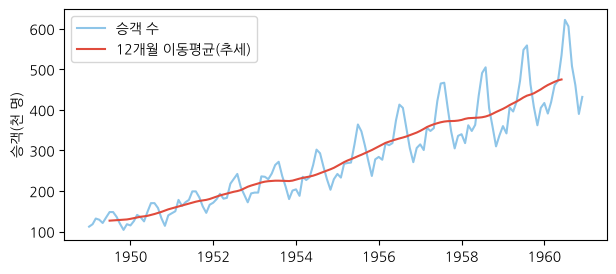

In [8]:
plt.figure(figsize=(7, 3))
plt.plot(y, color="#8EC5E8", label="승객 수")
plt.plot(trend, color="#E04B3C", label="12개월 이동평균(추세)")
plt.ylabel("승객(천 명)"); plt.legend(); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `plt.figure(figsize=(7, 3))` | 가로 7, 세로 3(인치)인 빈 판을 만든다 |
| `plt.plot(y, …, label=…)` | 시리즈를 선으로 그린다. 날짜 인덱스가 저절로 가로축이 된다 |
| `plt.ylabel( )`, `plt.legend( )` | 세로축 이름, 범례(선마다 붙인 label) |
| `plt.show( )` | 그린 판을 화면에 내보낸다 |

> **[분석 기법] 그래프는 네 줄이면 된다**
>
> 어떤 데이터든 틀은 같습니다. 판 만들기 `plt.figure(figsize=(가로, 세로))` → 그리기 `plt.plot(x, y)`(막대는 `시리즈.plot.bar( )`) → 이름 붙이기 `plt.ylabel( )`, `plt.legend( )` → 보이기 `plt.show( )`. 이 장의 그래프는 모두 이 틀에 색만 바꾼 것입니다. 숫자 하나로 요약하기 전에 늘 한 번 그려 봅니다.



**[결과 읽기]** 이동평균(빨강)은 매끈하게 오르고, 파란 선은 그 둘레에서 해마다 여름에 솟습니다. 솟음의 폭이 해가 갈수록 커지는 것은 실습 예제 12-2의 곱셈 분해로 이어집니다. 양 끝 여섯 달은 창이 모자라 추세가 비어 있습니다.

> **[직접 해보기]**
>
> ❶ `y.loc["1955"]`로 1955년만 꺼내, 가장 붐빈 달과 가장 한산한 달을 `idxmax( )`, `idxmin( )`으로 찾아보시오. (확인: 7월 364, 2월 233)
>
> ❷ 무게가 같은 가운데 맞춤 `y.rolling(12, center=True).mean( )`을 그려 빨간 추세와 견주어 보시오. 둘의 차이는 가장 커도 몇 천 명인가? (확인: 약 3.1천 명. 승객이 100~500천 명이니 무게를 나누는 방식은 결과를 거의 바꾸지 않는다)

> **[자주 나는 오류]**
>
> `KeyError: 'month'` → 열 이름은 대소문자까지 같아야 합니다. `air.columns`로 이름을 먼저 확인합니다.
>
> `Dot product shape mismatch, (13,) vs (12,)` → 창의 크기(13)와 무게의 개수가 다릅니다. `len(k)`를 찍어 봅니다.
>
> 그래프 가로축이 0, 1, 2…로 나온다 → `index_col`을 빠뜨려 날짜가 인덱스가 아닙니다. `y.index[:3]`이 날짜인지 확인합니다.

## [알고리즘 따라 하기 12-2] 두 해 여덟 분기로 계절 지수와 차분 익히기

어느 아이스크림 가게의 분기 판매량(천 개)이 두 해 동안 8, 12, 20, 10 / 10, 15, 25, 12였습니다. 분기마다 계절 지수를 구하고, 1차 차분과 계절 차분을 견주시오.

**❶ 해마다 평균으로 나누기(손 계산)**

**[손 계산]**

| 분기 | 첫해(평균 12.5) | 둘째 해(평균 15.5) | 계절 지수(두 비율의 평균) |
|---|---|---|---|
| 1분기 | 8 ÷ 12.5 = 0.64 | 10 ÷ 15.5 ≈ 0.65 | 0.64 |
| 2분기 | 12 ÷ 12.5 = 0.96 | 15 ÷ 15.5 ≈ 0.97 | 0.96 |
| 3분기 | 20 ÷ 12.5 = 1.60 | 25 ÷ 15.5 ≈ 1.61 | 1.61 |
| 4분기 | 10 ÷ 12.5 = 0.80 | 12 ÷ 15.5 ≈ 0.77 | 0.79 |

판매는 한 해에 24% 늘었는데(12.5 → 15.5) 비율은 거의 그대로입니다. "3분기는 그해 평균의 1.6배"처럼 계절이 비율로 움직이니 곱셈 모델이 맞습니다.

**❷ 코드로 계절 지수 구하기**

In [9]:
q8 = pd.Series([8, 12, 20, 10, 10, 15, 25, 12],
               index=pd.date_range("2023-01", periods=8, freq="QS"))
ratio = q8 / q8.groupby(q8.index.year).transform("mean")
season = ratio.groupby(ratio.index.quarter).mean()
print(ratio.round(2).values)
print("계절 지수:", season.round(2).to_dict())

[0.64 0.96 1.6  0.8  0.65 0.97 1.61 0.77]
계절 지수: {1: 0.64, 2: 0.96, 3: 1.61, 4: 0.79}


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `freq="QS"` | 분기 첫날(1, 4, 7, 10월 1일) 간격 |
| `.transform("mean")` | 해마다 평균을 구해 그해 네 칸에 똑같이 펼쳐 놓는다. `.mean( )`과 달리 길이가 8 그대로라 바로 나눌 수 있다 |
| `ratio.index.quarter` | 날짜에서 분기(1~4)만 꺼내 같은 분기끼리 묶는다 |


**결과 읽기.** 손 계산과 같은 0.64, 0.96, 1.61, 0.79입니다. 네 지수의 평균은 1이라, 1보다 크면 그 분기가 평소보다 붐빈다는 뜻입니다. 실습 예제 12-2의 `seasonal_decompose`는 해마다 평균 대신 12개월 이동평균으로 나눌 뿐 같은 생각입니다.

**❸ 1차 차분과 계절 차분**

In [10]:
print("1차 차분 :", q8.diff().dropna().astype(int).tolist())
print("계절 차분:", q8.diff(4).dropna().astype(int).tolist())

1차 차분 : [4, 8, -10, 0, 5, 10, -13]
계절 차분: [2, 3, 5, 2]


**결과 읽기.** 바로 앞 분기를 뺀 1차 차분(4, 8, −10, …)은 여전히 3분기에 크게 오르고 4분기에 크게 떨어져 계절이 남아 있습니다. 네 칸 앞(작년 같은 분기)을 뺀 계절 차분은 2, 3, 5, 2로 모두 양수이고 고릅니다. 계절은 지워지고 "한 해 사이 늘어난 양"만 남은 것입니다. 실습 예제 12-2에서는 월별 승객에 12칸 계절 차분을 씁니다.

## [실습 예제 12-2 ☆] 계절 지수와 정상성 검정

스태츠모델의 분해 함수로 승객 수를 추세, 계절, 나머지로 나누어 달별 계절 지수를 구하고, 로그와 차분을 거칠 때마다 ADF 검정의 p값을 구하시오.

**❶ 곱셈 분해로 계절 지수 구하기**

In [11]:
# 추세 × 계절 × 나머지
dec = seasonal_decompose(y, model="multiplicative", period=12)
# 계절 지수는 해마다 같으니 열두 달만
season = dec.seasonal.iloc[:12]
season.index = season.index.month                   # 날짜 대신 1~12월로
print("계절 지수 1월", round(season[1], 3), "/ 7월", round(season[7], 3),
      "/ 11월", round(season[11], 3))
print("열두 달 평균", round(season.mean(), 3))
# 한 달을 골라 세 부분을 곱해 본다
d = "1955-07-01"
T, S, R = dec.trend[d], dec.seasonal[d], dec.resid[d]
print(d[:7], "추세", round(T, 1), "× 계절", round(S, 3), "× 나머지", round(R,
                                                                    3),
      "=", round(T * S * R, 1),
      "/ 실제", y[d])

계절 지수 1월 0.91 / 7월 1.227 / 11월 0.801
열두 달 평균 1.0
1955-07 추세 285.8 × 계절 1.227 × 나머지 1.039 = 364.0 / 실제 364.0


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `seasonal_decompose(y, model="multiplicative", period=12)` | 1.2의 분해를 한 줄로 한다. 흔들림이 추세에 비례해 커지므로 곱하기로 나눈다. `period=12`는 열두 달마다 되풀이된다는 뜻(하루 데이터의 요일이면 7) |
| `dec.trend`, `dec.seasonal`, `dec.resid` | 분해된 세 부분. 모두 원자료와 같은 날짜 인덱스를 가진다 |
| `dec.seasonal.iloc[:12]` | 계절 지수는 해마다 같으므로 앞의 열두 달만 쓴다 |
| `season.index = season.index.month` | 줄 이름을 날짜에서 1~12(달 번호)로 바꾼다 |


**결과 읽기.** 7월의 계절 지수 1.227은 "그해 흐름보다 22.7% 붐빈다", 11월의 0.801은 "약 20% 한산하다"는 뜻입니다. 곱셈 분해의 계절 지수는 평균이 1이 되도록 맞춰집니다. 1955년 7월은 세 부분을 곱하면 실제 값이 그대로 나옵니다.

**❷ 로그를 씌우면 흔들림이 고르게 될까**

In [12]:
# 로그: 흔들림의 크기를 고르게
ly = np.log(y)
for name, s in {"원자료": y, "로그": ly}.items():
    sd = s.groupby(s.index.year).std()              # 해마다 열두 달의 흩어짐
    print(name, "1949년 표준편차", round(sd[1949], 3), "/ 1960년",
          round(sd[1960], 3),
          "→", round(sd[1960] / sd[1949], 1), "배")

원자료 1949년 표준편차 13.72 / 1960년 77.737 → 5.7 배
로그 1949년 표준편차 0.108 / 1960년 0.157 → 1.4 배


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `np.log(y)` | 모든 값에 자연로그를 씌운다. 되돌릴 때는 `np.exp( )` |
| `{"원자료": y, "로그": ly}.items( )` | 이름과 시리즈의 짝을 차례로 꺼낸다. 같은 계산을 두 시리즈에 되풀이할 때 쓰는 틀 |
| `groupby(s.index.year).std( )` | 해마다 열두 달 값의 표준편차, 곧 그해 계절 흔들림의 크기 |


**결과 읽기.** 원자료는 1960년의 흔들림이 1949년의 5.7배입니다. 로그를 씌우면 1.4배로 줄어 흔들림이 훨씬 고르게 됩니다. 로그는 "몇 배"의 변화를 "몇 칸"의 변화로 바꾸기 때문입니다.

> **[분석 기법] 로그 변환: 커질수록 커지는 흔들림 고르기**
>
> 값이 커질수록 흔들림도 커지면 로그를 씌웁니다. 로그는 곱하기를 더하기로 바꾸어 "몇 배"의 변화를 "몇 칸"의 변화로 만듭니다. 소득, 집값, 매출처럼 큰 값 몇 개가 꼬리를 길게 끄는 데이터도 `np.log( )`(0이 있으면 `np.log1p( )`)로 고르게 만든 뒤 분석합니다. 예측은 `np.exp( )`로 되돌리는 것을 잊지 않습니다.


**❸ 로그와 차분을 거치며 ADF 검정**

In [13]:
steps = {"원자료": y, "로그": ly, "로그+1차 차분": ly.diff(),
         "로그+1차+계절 차분": ly.diff().diff(12)}
for name, s in steps.items():
    p = adfuller(s.dropna(), autolag="AIC")[1]      # [1]이 p값
    print(f"{name:12s} 남은 개수 {s.notna().sum():3d}  ADF p값 {p:.4f}",
          "→ 고르다" if p < 0.05 else "→ 아직")

원자료          남은 개수 144  ADF p값 0.9919 → 아직


로그           남은 개수 144  ADF p값 0.4224 → 아직
로그+1차 차분     남은 개수 143  ADF p값 0.0711 → 아직
로그+1차+계절 차분  남은 개수 131  ADF p값 0.0002 → 고르다


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `ly.diff( )` | 1차 차분: 이번 달 − 지난달(식 12-2). 맨 앞 한 칸이 빈다 |
| `.diff(12)` | 계절 차분: 이번 달 − 작년 같은 달. 앞 열두 칸이 더 빈다 |
| `s.dropna( )` | 빈칸을 버린다. 검정 함수는 빈칸을 받지 않는다 |
| `adfuller(…, autolag="AIC")[1]` | ADF 검정. 돌려주는 여러 값 가운데 두 번째([1])가 p값. 시차 수는 AIC로 고른다 |
| `f"{name:12s} … {p:.4f}"` | f-글자: 중괄호 안의 값을 그 자리에 넣는다. `:12s`는 12칸 너비, `:.4f`는 소수 넷째 자리 |


**결과 읽기.** p값이 0.05 아래로 내려간 것은 계절 차분까지 한 뒤였습니다. 로그로 흔들림을, 1차 차분으로 추세를, 계절 차분으로 계절을 지운 셈이고, 이 순서가 4.4의 항공사 모델이 하는 일입니다. 차분할 때마다 앞쪽 값이 빠져 131개가 남았습니다.

> **[잠깐만요] ADF 검정과 p값**
>
> **ADF 검정**은 "이 시계열은 고르지 않다(정상성이 없다)"는 가정을 시험합니다. **p값**(5장)은 "그 가정이 맞다면 이런 데이터가 나올 확률"이라, 0.05보다 작으면 가정을 버리고 "고르다"고 봅니다. 어느 시계열이든 ARIMA를 쓰기 전에 차분이 몇 번 필요한지 이 검정으로 확인합니다.


**❹ 계절 지수와 분해 그래프**

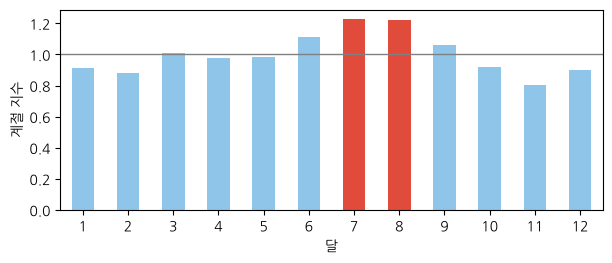

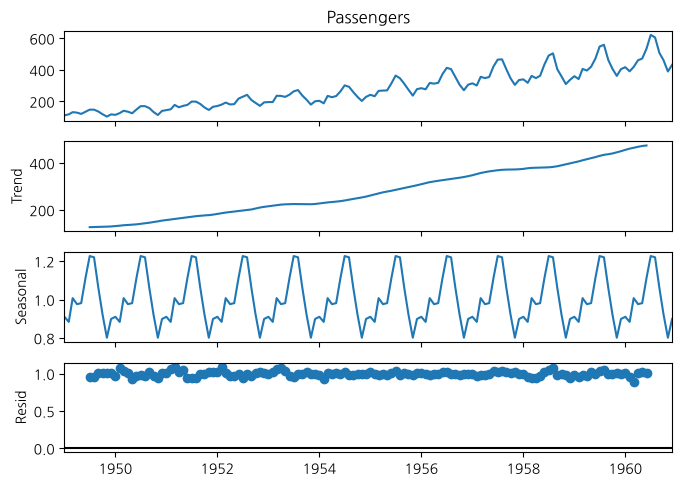

In [14]:
colors = ["#E04B3C" if m in (7, 8) else "#8EC5E8" for m in season.index]
season.plot.bar(color=colors,
                figsize=(7, 2.6), rot=0)
# 1보다 크면 그해 흐름보다 붐비는 달
plt.axhline(1, color="gray", lw=1)
plt.xlabel("달"); plt.ylabel("계절 지수"); plt.show()
# 원자료, 추세, 계절, 나머지 네 칸
fig = dec.plot()
fig.set_size_inches(7, 5); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `color=[… if m in (7, 8) else … for m in season.index]` | 달마다 색을 고르는 한 줄 반복: 7·8월은 빨강, 나머지는 하늘색 |
| `rot=0` | 가로축 글자(달 번호)를 눕히지 않고 바로 세운다 |
| `plt.axhline(1, …)` | 높이 1에 가로선을 긋는다. 계절 지수의 기준 |
| `dec.plot( )` | 분해 결과를 네 칸 그림으로 한 번에 그린다 |



**[결과 읽기]** 분해 그림의 셋째 칸(계절)은 해마다 똑같은 모양이 되풀이되고, 넷째 칸(나머지)은 1 둘레에서 작게 흔들립니다. 나머지에 아직 뚜렷한 무늬가 남아 있다면 분해가 놓친 것이 있다는 뜻입니다.

> **[직접 해보기]**
>
> ❶ `model="additive"`로 바꾸어 분해하고 7월 계절 값을 보시오. 단위는 무엇인가? (확인: 약 +63.8천 명. 덧셈 분해는 "몇 천 명 더"로, 곱셈 분해는 "몇 배"로 말한다)
>
> ❷ 로그 없이 원자료에 1차 차분과 계절 차분만 해서 ADF p값을 구해 보시오. (확인: 0.0000에 가깝다. 검정은 통과하지만 흔들림의 크기가 해마다 다른 것은 p값으로 드러나지 않는다. 그래서 그래프를 함께 본다)

> **[자주 나는 오류]**
>
> `ValueError: x must have 2 complete cycles requires 24 observations` → 분해에는 적어도 두 주기(24개월)가 필요합니다. 기간을 너무 짧게 잘랐는지 봅니다.
>
> `MissingDataError: exog contains inf or nans` → 차분으로 생긴 앞쪽 빈칸을 `dropna( )`로 버리지 않았습니다.
>
> `period`를 빠뜨렸는데 돌아간다 → 인덱스 간격(MS)에서 12를 짐작한 것입니다. 하루 데이터는 짐작이 맞지 않으니 늘 직접 씁니다.

## [알고리즘 따라 하기 12-3] 네 기준선 만들고 채점하기

알고리즘 따라 하기 12-2의 두 해 판매(8, 12, 20, 10 / 10, 15, 25, 12)로 셋째 해 네 분기를 예측합니다. 실제는 12, 18, 30, 14였습니다. 네 기준선의 예측을 만들고 MAE로 채점하시오. MAE를 내는 손 계산은 [예제 12-4]와 같습니다.

**❶ 네 기준선 만들기(손 계산)**

**[손 계산]**

| 기준선 | 만드는 법 | 셋째 해 예측 |
|---|---|---|
| 평균 | 여덟 값의 평균 112 ÷ 8 | 14, 14, 14, 14 |
| 직전 값 | 마지막 값(둘째 해 4분기) 그대로 | 12, 12, 12, 12 |
| 추세(drift) | 기울기 (12 − 8) ÷ 7 ≈ 0.57씩 더함 | 12.6, 13.1, 13.7, 14.3 |
| 작년 같은 분기 | 둘째 해 네 값을 그대로 | 10, 15, 25, 12 |

**❷ 코드로 채점하기**

In [15]:
tr8, te4 = q8.values.astype(float), np.array([12, 18, 30, 14])
step = (tr8[-1] - tr8[0]) / (len(tr8) - 1)        # 한 분기에 늘어나는 양
guess = {"평균": np.repeat(tr8.mean(), 4),
         "직전 값": np.repeat(tr8[-1], 4),
         "추세(drift)": tr8[-1] + step * np.arange(1, 5),
         "작년 같은 분기": tr8[-4:]}
for k, g in guess.items():
    print(g.round(1), "MAE", np.abs(te4 - g).mean().round(2), k)

[14. 14. 14. 14.] MAE 5.5 평균
[12. 12. 12. 12.] MAE 6.5 직전 값
[12.6 13.1 13.7 14.3] MAE 5.5 추세(drift)
[10. 15. 25. 12.] MAE 3.0 작년 같은 분기


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `q8.values.astype(float)` | 날짜를 떼고 값만 실수 배열로 꺼낸다 |
| `np.arange(1, 5)` | 1, 2, 3, 4. 한 분기 뒤, 두 분기 뒤 …에 기울기를 곱한다 |
| `tr8[-4:]` | 끝의 네 값, 곧 둘째 해 네 분기 |
| `np.abs(te4 - g).mean( )` | 틀린 크기의 평균, 곧 MAE(식 12-5) |
| `guess.items( )` | 사전에서 (이름, 예측) 짝을 하나씩 꺼낸다 |


**결과 읽기.** 계절이 뚜렷한 자료에서는 "작년 같은 분기"가 MAE 3.0으로 가장 잘 맞힙니다. 평균, 직전 값, 추세는 모두 3분기의 큰 판매(30)를 놓쳐 그 한 분기에서만 16~18을 틀렸습니다. 실습 예제 12-3은 같은 네 기준선을 승객 2년(24개월)으로 겨룹니다. 새 모델은 이 넷 가운데 가장 좋은 점수를 이겨야 쓸 만합니다.

## [실습 예제 12-3 ☆] 네 가지 기준선과 겨루기

1958년까지로 배우고 1959~1960년 24개월을 네 가지 기준선으로 예측해 MAE를 구하시오. 무작위로 섞어 나누면 점수가 어떻게 속이는지도 확인하시오.

**❶ 시간 순서대로 나누기**

In [16]:
# 1958년까지 학습, 1959~1960년 시험
train, test = y.loc[:"1958"], y.loc["1959":]
h = len(test)                                       # 내다볼 달 수
print("학습", len(train), "개월:", train.index[0].date(), "~",
      train.index[-1].date())
print("시험", h, "개월:", test.index[0].date(), "~", test.index[-1].date())

학습 120 개월: 1949-01-01 ~ 1958-12-01
시험 24 개월: 1959-01-01 ~ 1960-12-01


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `y.loc[:"1958"]` | 처음부터 1958년 끝까지. 날짜 인덱스에서는 글자 "1958"이 그해 열두 달 전체를 뜻하고, 끝 날짜까지 포함된다 |
| `y.loc["1959":]` | 1959년 1월부터 끝까지 |
| `h = len(test)` | 내다볼 칸 수(horizon). 기준선마다 이만큼 예측을 만든다 |
| `.date( )` | 날짜와 시각에서 날짜만 남긴다 |


**결과 읽기.** 학습 120개월 바로 다음 달부터 시험 24개월이 이어집니다. 두 기간이 겹치지도 비지도 않는지 끝 날짜와 첫 날짜로 확인합니다.

> **[자주 하는 실수] 시간이 있는 데이터를 무작위로 나누기**
>
> 8장의 `train_test_split( )`은 줄을 섞어 나눕니다. 시계열을 이렇게 나누면 1959년 3월을 맞히는 데 2월과 4월이 학습에 들어가 점수가 실제보다 좋게 나옵니다. 주문 기록, 센서, 환자 방문처럼 시각이 있는 데이터는 날짜로 자르거나 `shuffle=False`를 주어 앞쪽을 학습, 뒤쪽을 시험에 씁니다.


**❷ 네 기준선 만들기**

In [17]:
# 첫 값과 끝 값을 이은 기울기
slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
# 지금까지의 평균
base = {"평균": np.repeat(train.mean(), h),
        # 마지막 값 그대로
        "직전 값": np.repeat(train.iloc[-1], h),
        # 기울기대로 연장
        "추세(drift)": train.iloc[-1] + slope * np.arange(1, h + 1),
        # 1958년 열두 달을 두 번
        "작년 같은 달": np.tile(train.iloc[-12:].values, 2)}
look = pd.DataFrame(base, index=test.index).round(1)
# 맨 앞에 실제 값 열을 끼운다
look.insert(0, "실제", test)
print(look.head(4).to_string())
print("한 달에 늘어나는 양(기울기):", round(slope, 2), "천 명")

               실제     평균   직전 값  추세(drift)  작년 같은 달
Month                                              
1959-01-01  360.0  245.9  337.0      338.9    340.0
1959-02-01  342.0  245.9  337.0      340.8    318.0
1959-03-01  406.0  245.9  337.0      342.7    362.0
1959-04-01  396.0  245.9  337.0      344.6    348.0
한 달에 늘어나는 양(기울기): 1.89 천 명


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `train.iloc[-1]`, `train.iloc[0]` | 위치로 고르기: 마지막 값, 첫 값. `loc`은 이름(날짜), `iloc`은 순서 번호 |
| `np.repeat(값, h)` | 같은 값을 h번 늘어놓는다 |
| `np.arange(1, h + 1)` | 1, 2, …, 24. 한 달 뒤, 두 달 뒤 …에 기울기를 곱한다 |
| `np.tile(배열, 2)` | 배열을 통째로 두 번 잇는다. `iloc[-12:]`는 1958년 열두 달 |
| `.values` | 날짜 인덱스를 떼고 값만. 떼지 않으면 1958년 날짜가 따라와 시험 기간 날짜와 맞지 않는다 |
| `pd.DataFrame(base, index=test.index)` | 사전의 키가 열 이름, 값이 열이 된다. 줄 이름은 시험 기간 날짜 |
| `look.insert(0, "실제", test)` | 0번 자리(맨 앞)에 열을 끼운다 |


**결과 읽기.** 평균과 직전 값은 24개월 내내 같은 값을 적고, 추세는 한 달에 1.9천 명씩 올라가며, 작년 같은 달만 1958년의 계절 모양을 그대로 따라갑니다.

**❸ 채점하고 그래프로 견주기**

평균           206.3
직전 값         115.2
추세(drift)     91.6
작년 같은 달       71.2
가장 좋은 기준선: 작년 같은 달 / 평균으로 찍기보다 65 % 작다


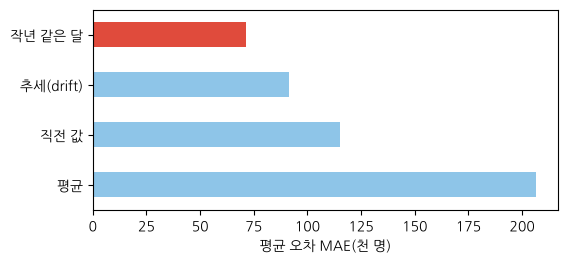

In [18]:
score = pd.Series({k: mae(test, f) for k, f in base.items()})
print(score.to_string())
best = score.idxmin()
print("가장 좋은 기준선:", best, "/ 평균으로 찍기보다",
      round((1 - score[best] / score["평균"]) * 100), "% 작다")
score.plot.barh(color=["#8EC5E8"] * 3 + ["#E04B3C"], figsize=(6, 2.6))
plt.xlabel("평균 오차 MAE(천 명)"); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `{k: mae(test, f) for k, f in base.items( )}` | 기준선마다 같은 채점 함수로 점수를 매겨 사전에 담는다 |
| `pd.Series(사전)` | 사전을 이름 붙은 숫자 줄로. 정렬, 그래프가 쉬워진다 |
| `score.idxmin( )` | 가장 작은 값의 이름 |
| `.plot.barh( )` | 가로 막대. 이름이 긴 항목을 견줄 때 읽기 좋다 |



**결과 읽기.** 계절을 아는 "작년 같은 달"(71.2)이 이 데이터에서 모델이 넘어야 할 선입니다. 평균으로 찍기보다 65% 작게 틀립니다. 직전 값(115.2)이 추세보다 나쁜 것은 1958년 12월(337)이 한산한 달인데 그 값을 여름까지 끌고 가기 때문입니다.

> **[분석 기법] 기준선 모델: "아무 생각 없이"도 이만큼은 맞힌다**
>
> 모델의 성적은 가장 단순한 방법과 견줄 때 뜻이 생깁니다. 집값이면 "평균 집값", 스팸 분류면 "모두 정상 메일", 시계열이면 "직전 값"이나 "작년 같은 때"가 기준선이고, 사이킷런의 `DummyRegressor`, `DummyClassifier`가 이 일을 합니다. 보고할 때는 "MAE 39.4"가 아니라 "기준선 71.2보다 45% 작다"처럼 말합니다.


**❹ 무작위로 섞어 나누면 점수가 속인다**

In [19]:
# 같은 난수가 나오도록 씨앗 0
rng = np.random.default_rng(0)
# 아무 달 24개
pick = np.sort(rng.choice(np.arange(1, len(y) - 1), size=24, replace=False))
guess = (y.shift(1) + y.shift(-1)) / 2              # 앞달과 뒷달의 평균
print("섞어 뽑은 24개월을 앞뒤 달 평균으로 맞히면 MAE",
      mae(y.iloc[pick], guess.iloc[pick]))
print("같은 방법을 1959~1960년에 쓰면 → 1961년 1월 값이 필요하다:",
      guess.loc["1960-12-01"])

섞어 뽑은 24개월을 앞뒤 달 평균으로 맞히면 MAE 16.6
같은 방법을 1959~1960년에 쓰면 → 1961년 1월 값이 필요하다: nan


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `np.random.default_rng(0)` | 난수 발생기. 씨앗(0)을 정하면 누가 돌려도 같은 달이 뽑힌다 |
| `rng.choice(…, size=24, replace=False)` | 겹치지 않게 24개를 뽑는다. 맨 앞과 맨 끝 달은 앞뒤가 없어 뺐다 |
| `y.shift(1)`, `y.shift(-1)` | 한 칸 뒤로 밀면 그 자리에 앞달 값이, 앞으로 당기면 뒷달 값이 온다 |
| `guess.iloc[pick]` | 뽑은 순서 번호의 값만 |


**결과 읽기.** 섞어 나누면 아무 모델 없이 앞뒤 달의 평균만으로 MAE가 16.6이 되어, 가장 좋은 기준선(71.2)보다 네 배 넘게 좋아 보입니다. 하지만 실제로 1960년 12월을 예측할 때 1961년 1월 값은 없습니다(NaN). 이 점수는 미래를 엿본 대가입니다.

> **[직접 해보기]**
>
> ❶ 학습 끝을 1957년으로 당겨(`y.loc[:"1957"]`) 1958~1959년을 네 기준선으로 예측하면 1등이 바뀌는가? (확인: 여전히 작년 같은 달이 1등, MAE 36.2)
>
> ❷ "작년 같은 달"에 1958년이 1957년보다 늘어난 비율(`train.loc["1958"].sum( ) / train.loc["1957"].sum( )`)을 곱해 보시오. MAE가 줄어드는가? (확인: 비율 1.034, MAE 58.2로 줄어든다. 계절 기준선에 추세를 얹은 셈이다)

> **[자주 나는 오류]**
>
> `ValueError: Length of values (12) does not match length of index (24)` → 기준선 하나의 길이가 시험 기간과 다릅니다. `np.tile(…, 2)`의 2를 빠뜨렸는지 봅니다.
>
> `ValueError: cannot insert 실제, already exists` → `insert` 줄만 따로 한 번 더 실행해 같은 열을 또 끼우려 한 것입니다. 노트북은 앞서 만든 표를 기억하므로, ❷ 칸 전체를 다시 실행해 `look`을 새로 만듭니다.

## [알고리즘 따라 하기 12-4] 지수평활을 반복문으로, 판다스로

다섯 달 판매 10, 12, 14, 13, 15에 α = 0.3, 첫 평활값 s₁ = 10으로 지수평활(식 12-4)을 하고, 여섯째 달을 예측하시오.

[예제 12-3]에서 손으로 한 계산(10 → 10.6 → 11.62 → …)을 반복문과 판다스로 다시 합니다.

**❶ 같은 계산을 반복문으로**

In [20]:
y5, alpha = [10, 12, 14, 13, 15], 0.3
s = [y5[0]]                                     # s₁ = 첫 값
for v in y5[1:]:
    s.append(alpha * v + (1 - alpha) * s[-1])   # 식 12-4
print([round(x, 2) for x in s], "→ 여섯째 달 예측", round(s[-1], 2))

[10, 10.6, 11.62, 12.03, 12.92] → 여섯째 달 예측 12.92


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `s = [y5[0]]` | 평활값 목록을 첫 값 하나로 시작한다 |
| `for v in y5[1:]:` | 둘째 값부터 차례로 꺼낸다 |
| `s[-1]` | 목록의 마지막, 곧 바로 앞 평활값 sₜ₋₁ |
| `s.append( )` | 새 평활값을 목록 끝에 붙인다 |


**❷ 판다스로 확인하고 α 바꿔 보기**

In [21]:
p5 = pd.Series(y5, dtype=float)
look5 = pd.DataFrame({"판매": p5,
                      "α=0.3": p5.ewm(alpha=0.3, adjust=False).mean(),
                      "α=0.8": p5.ewm(alpha=0.8, adjust=False).mean()})
print(look5.round(2).to_string())

     판매  α=0.3  α=0.8
0  10.0  10.00  10.00
1  12.0  10.60  11.60
2  14.0  11.62  13.52
3  13.0  12.03  13.10
4  15.0  12.92  14.62


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `p5.ewm(alpha=0.3)` | 지수 무게(exponentially weighted) 창을 만든다 |
| `adjust=False` | 식 12-4 그대로 한 줄씩 섞는다. 빼면 앞쪽 무게를 다시 맞춘 다른 식이 된다 |
| `.mean( )` | 그 무게로 평균, 곧 평활값을 낸다 |


**결과 읽기.** α = 0.3 열이 반복문의 결과와 같습니다. α = 0.8은 새 값을 바짝 따라가 마지막 값 14.65가 실제 15에 가깝고, α = 0.3은 12.92로 한참 뒤처집니다. 오르는 자료에서 단순 지수평활은 늘 늦게 따라가므로, 실습 예제 12-4의 홀트-윈터스는 수준에 더해 추세와 계절도 따로 평활합니다.

## [실습 예제 12-4 ☆] 항공사 모델, 홀트-윈터스, 기준점 옮기기

항공사 모델과 홀트-윈터스로 1959~1960년을 예측하고, 1955~1960년을 해마다 그 전해까지로 배워 예측해 두 모델과 결합 예측을 견주시오.

**❶ 두 모델을 함수로 만들기**

In [22]:
# 항공사 모델: 로그 + 계절 ARIMA
def airline(series):
    return SARIMAX(np.log(series), order=(0, 1, 1),
                   seasonal_order=(0, 1, 1, 12)).fit(disp=False)
# 홀트-윈터스: 추세 + 곱셈 계절
def holt(series):
    return ExponentialSmoothing(series, trend="add", seasonal="mul",
                                seasonal_periods=12).fit()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `SARIMAX(np.log(series), …)` | 로그를 씌운 승객 수로 계절 ARIMA 모델을 세운다(실습 예제 12-2에서 로그가 흔들림을 고르게 했다) |
| `order=(0, 1, 1)` | (p, d, q): 자기 과거 값은 쓰지 않고(0), 1차 차분을 한 번(1), 직전 오차 하나를 더한다(1) |
| `seasonal_order=(0, 1, 1, 12)` | 같은 일을 열두 달 단위로: 계절 차분 한 번, 작년 같은 달의 오차 하나 |
| `.fit(disp=False)` | 계수를 데이터에 맞춘다. `disp=False`는 계산 과정을 찍지 않게 한다 |
| `ExponentialSmoothing(…, trend="add", seasonal="mul", seasonal_periods=12)` | 홀트-윈터스(4.3): 수준, 더하는 추세, 곱하는 계절을 지수평활로 갱신한다 |
| `def airline(series): return …` | 모델을 함수로 싸 두면 ❸에서 기간만 바꿔 다시 부를 수 있다 |

이 칸은 함수를 만들기만 하므로 출력이 없습니다.

**❷ 한 번 맞추고 95% 예측 구간 재기**

In [23]:
sar = airline(train)
print("계수 θ(직전 오차)", round(sar.params["ma.L1"], 3),
      "/ Θ(작년 같은 달 오차)", round(sar.params["ma.S.L12"], 3))
# 로그로 배웠으니 exp로 되돌린다
p_sar = np.exp(sar.forecast(h))
p_hw = holt(train).forecast(h)
print("항공사 모델 MAE", mae(test, p_sar), "/ 홀트-윈터스 MAE", mae(test,
                                                          p_hw),
      "/ 작년 같은 달", score["작년 같은 달"])
# 95% 예측 구간(아래, 위)
ci = np.exp(sar.get_forecast(h).conf_int(alpha=0.05))
inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).sum()
print("95% 구간 안에 든 달:", inside, "/", h)
print("구간 폭 1959-01:", round(ci.iloc[0, 1] - ci.iloc[0, 0], 1),
      "→ 1960-12:", round(ci.iloc[-1, 1] - ci.iloc[-1, 0], 1))

계수 θ(직전 오차) -0.342 / Θ(작년 같은 달 오차) -0.541
항공사 모델 MAE 39.4 / 홀트-윈터스 MAE 29.0 / 작년 같은 달 71.2
95% 구간 안에 든 달: 24 / 24
구간 폭 1959-01: 51.2 → 1960-12: 239.5


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `sar.params["ma.L1"]` | 맞춘 계수 가운데 직전 오차의 무게 θ. `ma.S.L12`는 작년 같은 달 오차의 무게 Θ |
| `sar.forecast(h)` | 학습 끝 다음 달부터 h개월을 예측한다. 로그 단위이므로 `np.exp( )`로 승객 수로 되돌린다 |
| `get_forecast(h).conf_int(alpha=0.05)` | 예측마다 95% 구간의 아래·위 끝을 두 열로 준다(6.3). 이것도 로그 단위라 exp |
| `(test >= 아래) & (test <= 위)` | 달마다 "구간 안에 들었나"를 참·거짓으로. `&`는 "그리고", `.sum( )`은 참의 개수 |
| `ci.iloc[0, 1] - ci.iloc[0, 0]` | 첫째 줄의 위 끝 − 아래 끝 = 구간 폭 |


**결과 읽기.** 두 모델 모두 기준선(71.2)의 절반쯤만 틀립니다. 이번 한 번은 홀트-윈터스가 이겼습니다. 95% 구간에 24개월이 모두 들어 구간이 넉넉한 편이고, 폭은 첫 달 51.2천 명에서 24개월 뒤 239.5천 명으로 넓어집니다. 계수 θ와 Θ가 음수인 것은 "지난번 충격의 일부를 되돌린다"는 뜻입니다.

> **[더 알아보기] 항공사 모델을 식으로 쓰면**
>
> 로그 승객 수 zₜ = ln yₜ에 1차 차분과 계절 차분을 한 값을 이번 달의 충격 εₜ와 지난달, 작년 같은 달의 충격으로 설명합니다. (zₜ − zₜ₋₁) − (zₜ₋₁₂ − zₜ₋₁₃) = εₜ + θεₜ₋₁ + Θεₜ₋₁₂ + θΘεₜ₋₁₃. 1958년까지로 맞추면 θ = −0.342, Θ = −0.541입니다(❷ 결과).
>
> 여러 후보는 흔히 **AIC**(잘 맞는 정도와 단순함을 함께 따지는 점수, 작을수록 좋다)로 고릅니다(`sar.aic`). 다만 차분 차수(d, D)가 다른 모델끼리는 설명하려는 데이터 자체가 달라 AIC를 견줄 수 없습니다. d와 D를 먼저 정하고(실습 예제 12-2), 그다음 p, q, P, Q를 AIC로 고릅니다.

**❸ 기준점을 한 해씩 옮기며 시험하기**

In [24]:
rows = []
# 1955~1960년을 차례로 시험
for Y in range(1955, 1961):
    # 그 전해까지 학습, 그해 시험
    tr, te = y.loc[:str(Y - 1)], y.loc[str(Y)]
    f_sn = tr.iloc[-12:].values                     # 작년 같은 달
    f_sar = np.exp(airline(tr).forecast(12)).values
    f_hw = holt(tr).forecast(12).values
    rows.append({"시험 해": Y, "작년 같은 달": mae(te, f_sn),
                 "SARIMA": mae(te, f_sar), "홀트-윈터스": mae(te, f_hw),
                 "둘의 평균": mae(te, (f_sar + f_hw) / 2)})
roll = pd.DataFrame(rows).set_index("시험 해")
print(roll.to_string())
print("해마다 1등:", roll.iloc[:, :3].idxmin(axis=1).value_counts().to_dict())
print("여섯 해 평균:", roll.mean().round(1).to_dict())

      작년 같은 달  SARIMA  홀트-윈터스  둘의 평균
시험 해                                
1955     45.1    14.3    19.5   16.9
1956     44.2     5.6    10.0    5.8
1957     40.2     6.4    14.6    9.4
1958     12.6    27.6    13.9   19.5
1959     47.3    29.4    20.2   24.5
1960     47.8    13.3    10.3   10.9
해마다 1등: {'SARIMA': 3, '홀트-윈터스': 2, '작년 같은 달': 1}
여섯 해 평균: {'작년 같은 달': 39.5, 'SARIMA': 16.1, '홀트-윈터스': 14.8, '둘의 평균': 14.5}


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `rows = []` … `rows.append({…})` | 해마다 성적을 사전 하나로 만들어 목록에 쌓는다. 반복이 끝나면 표로 바꾼다 |
| `for Y in range(1955, 1961)` | 1955, …, 1960. 끝 수(1961)는 들어가지 않는다 |
| `y.loc[:str(Y - 1)]` | 시험 해의 전해 끝까지. 날짜 고르기에는 글자가 필요해 `str( )`로 바꾼다 |
| `(f_sar + f_hw) / 2` | 결합 예측: 두 예측을 더해 2로 나누기만 하면 된다 |
| `pd.DataFrame(rows).set_index("시험 해")` | 사전의 목록 → 표, "시험 해" 열을 줄 이름으로 |
| `roll.iloc[:, :3].idxmin(axis=1)` | 앞 세 열(단독 방법)만 놓고, 줄마다(해마다) 가장 작은 열 이름. `axis=1`은 "옆으로" |


**결과 읽기.** 한 번(1959~1960년) 시험하면 홀트-윈터스가 이기지만, 여섯 번 시험하니 1등이 셋으로 갈리고, 평균은 둘의 평균이 가장 좋았습니다(3.6과 같은 결론). 작년 같은 달도 한 해는 1등을 했습니다.

> **[분석 기법] 기준점을 옮기며 여러 번 시험하기**
>
> 시험을 한 번만 하면 그해의 운이 성적을 정합니다. 기준점을 옮기며 "그 전까지로 배우고 다음을 맞히기"를 되풀이하면(**워크 포워드 검증**) 평균과 최악을 함께 볼 수 있습니다. 사이킷런의 `TimeSeriesSplit(n_splits=5)`이 이 나누기를 해 줍니다. 8장의 교차 검증과 같은 생각이지만 학습이 늘 시험보다 앞섭니다.


**❹ 예측과 구간 그래프**

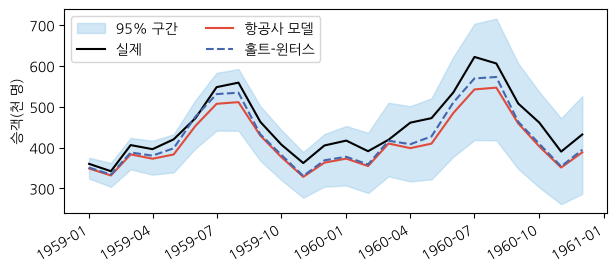

In [25]:
plt.figure(figsize=(7, 3))
# 아래·위 끝 사이를 칠한다
plt.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1],
                 color="#8EC5E8", alpha=0.4, label="95% 구간")
plt.plot(test, color="black", label="실제")
plt.plot(p_sar, color="#E04B3C", label="항공사 모델")
plt.plot(p_hw, color="#4466AE", ls="--", label="홀트-윈터스")
# 날짜 글자를 비스듬히 눕혀 겹치지 않게
plt.gcf().autofmt_xdate()
plt.ylabel("승객(천 명)"); plt.legend(ncol=2); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `plt.fill_between(x, 아래, 위, alpha=0.4)` | 두 선 사이를 칠한다. `alpha`는 투명도(0 투명 ~ 1 불투명) |
| `ls="--"` | 선 모양을 점선으로. 색이 비슷해도 흑백 인쇄에서 구별된다 |
| `plt.gcf( ).autofmt_xdate( )` | 지금 판(gcf)의 날짜 글자를 비스듬히 눕힌다 |
| `legend(ncol=2)` | 범례를 두 줄로 나란히 |


**[결과 읽기]** 두 모델 모두 여름의 솟음과 늦가을의 꺼짐을 따라갑니다. 항공사 모델(빨강)은 1960년 여름을 조금 높게 잡았고, 실제 값(검정)은 끝까지 하늘색 띠 안에 있습니다.

> **[분석 기법] 결합 예측: 둘의 평균이 하나보다 낫다**
>
> 서로 다르게 틀리는 두 예측을 평균하면 한쪽이 높게, 다른 쪽이 낮게 틀린 날 오차가 서로 깎여 크게 지는 해가 줄어듭니다. 10장의 랜덤 포레스트가 나무 수백 그루의 평균인 것도 같은 원리입니다(**앙상블**). 단, 둘이 똑같이 틀리면 평균해도 나아지지 않습니다.


> **[직접 해보기]**
>
> ❶ 홀트-윈터스의 `seasonal="mul"`을 `"add"`로 바꾸면 1959~1960년 MAE는 어떻게 되는가? (확인: 31.1로 조금 나빠진다. 흔들림이 커지는 데이터에는 곱셈 계절이 맞다)
>
> ❷ 항공사 모델의 `order`를 `(1, 1, 1)`로 바꾸어 AIC(`.aic`)를 견주어 보시오. (확인: (0,1,1)은 −389.0, (1,1,1)은 −387.3. 계수를 하나 더 넣어도 나아지지 않으니 단순한 쪽을 고른다)

> **[자주 나는 오류]**
>
> 예측값이 5.9, 6.1처럼 작게 나온다 → 로그 단위 그대로입니다. `np.exp( )`로 되돌렸는지 봅니다.
>
> `ConvergenceWarning: Maximum Likelihood optimization failed to converge` → 계수 찾기가 끝까지 수렴하지 않았다는 경고입니다. 결과는 나오지만 `fit(maxiter=200)`처럼 반복을 늘려 다시 맞춰 봅니다.
>
> `KeyError: 'ma.L1'` → 모델의 차수가 바뀌면 계수 이름도 바뀝니다. `sar.params`를 통째로 찍어 이름을 확인합니다.

### 한국 전력 파일 받기

코랩 파일 창에 파일을 올려 두었다면 이 셀은 건너뜁니다. 없으면 책 저장소(ch12/data)에서 받아 옵니다.

In [26]:
import os, urllib.parse, urllib.request
KPX = "kpx_시간별_전국_전력수요량_2021_2025.csv"
if not os.path.exists(KPX):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/yeonu69/bigdata-python-book/main/ch12/data/" + urllib.parse.quote(KPX), KPX)
print(os.path.getsize(KPX), "bytes")

370845 bytes


## [실습 예제 12-5 ★] 한국 전력 데이터 불러오고 가장 높은 날 확인하기

한국전력거래소의 시간별 전력 수요 파일을 읽어 신원을 확인하고, 하루 단위(GWh)로 바꾼 뒤 가장 많이 쓴 날과 가장 적게 쓴 날을 찾으시오(03절 3.1, 3.4).

**❶ 읽고 생김새 보기**

In [27]:
# 파일을 둔 폴더(코랩 파일 창에 올렸으면 빈 글자)
DATA = ""
kp = pd.read_csv(DATA + "kpx_시간별_전국_전력수요량_2021_2025.csv")
print(kp.shape)
print(kp.iloc[:2, :5])                              # 앞 두 줄, 앞 다섯 열만
print(kp.tail(2).iloc[:, :3])                       # 끝 두 줄

(1827, 25)
           날짜       1시       2시       3시       4시
0  2021-01-01  64942.0  62593.0  60905.0  59889.0
1  2021-01-02  60658.0  58603.0  57309.0  56663.0
              날짜       1시       2시
1825  2025-12-31  65511.0  62817.0
1826         NaN      NaN      NaN


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `DATA + "kpx_….csv"` | 폴더 이름과 파일 이름을 이어 붙인다. 구글 드라이브에 두었다면 `DATA = "/content/drive/MyDrive/"`처럼 고친다 |
| `kp.shape` | (줄 수, 열 수). 다섯 해면 1,826줄 안팎이어야 한다 |
| `kp.iloc[:2, :5]` | 위치로 앞 두 줄, 앞 다섯 열만 본다. 열이 25개라 한꺼번에 찍으면 잘린다 |
| `kp.tail(2)` | 끝 두 줄. 파일 끝에 딸려 온 빈 줄이 있는지 여기서 보인다 |


**결과 읽기.** 하루가 한 줄이고, 날짜 열 하나와 1시~24시의 MW(그 시각에 쓰는 전력) 열 24개입니다. 끝줄은 날짜까지 비어 있는 줄(NaN)입니다.

> **[더 알아보기] 포털에서 직접 받아 합치기**
>
> 공공데이터포털에는 해마다 파일이 하나씩 있고, 책의 파일은 2021~2025년 다섯 파일을 차례로 이은 것입니다. 직접 합칠 때는 세 가지를 챙깁니다. 한글이 cp949로 저장되어 있으니 `pd.read_csv(파일, encoding="cp949")`로 읽습니다. 해마다 열 이름을 같게 맞춘 뒤 `pd.concat([표1, 표2, …])`로 잇습니다. 이은 뒤에는 날짜순으로 정렬하고 같은 날짜는 하나만 남깁니다(`drop_duplicates( )`).

**❷ 신원 확인하고 날짜 인덱스 세우기**

In [28]:
print("빈칸이 있는 줄:", kp.isna().any(axis=1).sum())
kp = kp.dropna(subset=["날짜"])                      # 날짜까지 빈 줄은 버린다
kp["날짜"] = pd.to_datetime(kp["날짜"])
# 날짜를 인덱스로, 빠진 날은 빈 줄로 드러낸다
kp = kp.set_index("날짜").asfreq("D")
print("기간:", kp.index[0].date(), "~", kp.index[-1].date(), "/", len(kp),
      "일")
print("같은 날짜:", kp.index.duplicated().sum(), "/ 날짜 순서대로:",
      kp.index.is_monotonic_increasing,
      "/ 남은 빈칸:", kp.isna().sum().sum())

빈칸이 있는 줄: 1
기간: 2021-01-01 ~ 2025-12-31 / 1826 일
같은 날짜: 0 / 날짜 순서대로: True / 남은 빈칸: 0


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `kp.isna( ).any(axis=1).sum( )` | 칸마다 빈칸인지(`isna`) → 줄마다 하나라도 비었는지(`any(axis=1)`) → 그런 줄의 수 |
| `dropna(subset=["날짜"])` | 날짜 열이 빈 줄만 버린다. `subset` 없이 쓰면 한 칸만 비어도 줄을 버린다 |
| `pd.to_datetime( )` | 글자 "2021-01-01"을 날짜로 바꾼다. 읽을 때 `parse_dates`를 주는 것과 같다 |
| `set_index("날짜").asfreq("D")` | 날짜를 인덱스로 세우고 하루 간격을 정한다. 빠진 날이 있으면 빈 줄이 새로 생긴다 |
| `index.duplicated( ).sum( )` | 같은 날짜가 두 번 나온 줄의 수 |
| `is_monotonic_increasing` | 날짜가 처음부터 끝까지 커지기만 하는가 |
| `isna( ).sum( ).sum( )` | 열마다 빈칸 수 → 그 합 = 표 전체의 빈칸 수 |


**결과 읽기.** 빈 줄 하나를 버리자 다섯 해 1,826일이 빠진 날도, 겹친 날도 없이 날짜 순서대로 남았습니다. 2024년이 윤년이라 365 × 5 + 1입니다.

> **[분석 기법] 데이터 신원 확인 네 가지**
>
> 어떤 데이터든 분석 전에 ① 크기와 기간 `shape`, ② 빈칸 `isna( ).sum( )`, ③ 같은 줄 `index.duplicated( ).sum( )`, ④ 순서 `index.is_monotonic_increasing`을 확인합니다. 빈칸은 왜 비었는지부터 묻습니다. 이 파일의 빈 줄은 여러 해의 파일을 이어 붙일 때 끝에 딸려 온 줄이라 버렸습니다. 값이 있어야 할 날이 비었다면 버리지 말고 그 까닭을 먼저 찾습니다.


**❸ 하루 GWh로 바꾸고, 가장 많이 쓴 날과 적게 쓴 날 찾기**

In [29]:
# 하루 GWh = 24시간 평균(MW) × 24 ÷ 1000
c = kp.mean(axis=1) * 24 / 1000
print(len(c), "일 / 하루 평균", round(c.mean(), 1), "GWh")
print("해마다 평균:", c.groupby(c.index.year).mean().round(1).to_dict())
print("가장 많은 날\n" + c.nlargest(3).round(1).to_string(header=False))
print("가장 적은 날\n" + c.nsmallest(3).round(1).to_string(header=False))
d = c.idxmax()
print("그날 가장 많이 쓴 시각:", kp.loc[d].idxmax(), int(kp.loc[d].max()),
      "MW")

1826 일 / 하루 평균 1550.7 GWh
해마다 평균: {2021: 1529.7, 2022: 1573.8, 2023: 1553.3, 2024: 1548.8, 2025: 1548.1}
가장 많은 날
2024-08-20    1996.9
2022-12-23    1992.3
2024-08-21    1965.0
가장 적은 날
2023-10-01    1089.2
2023-09-29    1101.4
2025-05-04    1102.9
그날 가장 많이 쓴 시각: 17시 97115 MW


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `kp.mean(axis=1)` | 24개 열을 옆으로 평균한다(하루의 평균 MW). `axis=0`이면 열마다 아래로 평균 |
| `* 24 / 1000` | 평균 MW × 24시간 = 하루의 MWh, ÷ 1,000 = GWh |
| `c.nlargest(3)` | 가장 큰 세 값을 날짜와 함께 큰 순서로. 작은 쪽은 `nsmallest` |
| `.to_string(header=False)` | 시리즈를 이름 줄 없이 글자로 바꾼다. `print`에 이어 붙이기 좋다 |
| `kp.loc[d]` | 그날 한 줄(24시간)만. `.idxmax( )`는 가장 큰 열 이름, 곧 시각 |


**결과 읽기.** 하루 평균은 1,550.7 GWh이고, 해마다 평균은 1,530~1,574 GWh로 계단처럼 뛴 해가 없습니다. 가장 많은 날은 2024년 8월 20일(폭염)과 2022년 12월 23일(한파), 가장 적은 날은 2023년 추석 연휴와 2025년 어린이날 연휴입니다. 오류가 아니라 사건입니다(3.4). 2024년 8월 20일 17시의 97,115 MW는 그때까지의 역대 최대로 발표된 값과 같습니다.

> **[분석 기법] 튀는 값은 지우기 전에 확인한다**
>
> 가장 크거나 작은 값 몇 개를 날짜와 함께 꺼내(`nlargest`, `nsmallest`) 바깥의 사실과 맞춰 봅니다. 달력(명절, 휴일), 날씨(폭염, 한파), 뉴스(행사, 사고)로 설명되면 **사건**이니 남기고, 설명되지 않으면 단위, 입력 실수, 집계 기준 변경 같은 **오류**를 의심합니다. 매출 기록의 최고 매출일이 블랙 프라이데이인지, 0이 하나 더 붙은 입력인지 가리는 것과 같습니다. 사건을 오류로 알고 지우면 모델은 폭염과 명절을 배울 기회를 잃습니다.


**❹ 다섯 해 그래프에 두 날 표시하기**

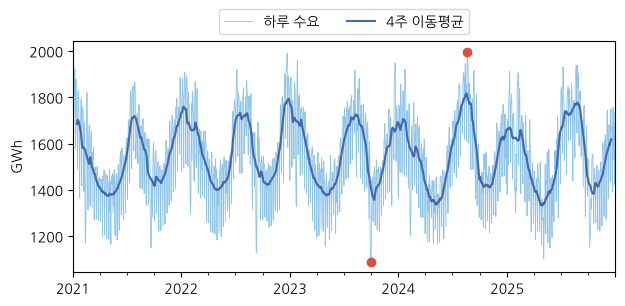

In [30]:
c.plot(color="#8EC5E8", lw=0.6, figsize=(7, 3), label="하루 수요")
# 요일 톱니를 지운다
c.rolling(28, center=True).mean().plot(color="#4466AE", label="4주 이동평균")
plt.scatter([c.idxmax(), c.idxmin()], [c.max(), c.min()], color="#E04B3C",
            zorder=3)
plt.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1))
plt.ylabel("GWh"); plt.xlabel(""); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `c.plot(lw=0.6, …)` | 시리즈의 그리기 함수. 날짜 인덱스를 가로축으로 쓴다. `lw`는 선 굵기 |
| `c.rolling(28, center=True).mean( )` | 4주(28일) 이동평균. 28은 7의 배수라 요일의 톱니가 깨끗이 지워진다 |
| `plt.scatter(가로 목록, 세로 목록, zorder=3)` | 점을 찍는다. `zorder`가 크면 선 위에 올라온다 |
| `bbox_to_anchor=(0.5, 1)` | 범례를 그래프 위 바깥, 가운데에 둔다 |


**[결과 읽기]** 해마다 여름과 겨울에 두 번 솟고 봄·가을에 꺼지는 "쌍봉" 모양입니다. 냉방과 난방이 모두 전기를 쓰기 때문입니다. 하늘색 선의 톱니는 요일, 아래로 깊게 꺼진 곳은 설과 추석입니다.

> **[직접 해보기]**
>
> ❶ 열마다 평균(`kp.mean( )`)을 구해 하루 가운데 가장 많이 쓰는 시각과 가장 적게 쓰는 시각을 찾으시오. (확인: 가장 많은 시각은 19시 71.6 GW, 가장 적은 시각은 4시 56.4 GW. 다섯 해를 평균하면 저녁에 가장 많이 쓴다)
>
> ❷ `c.resample("MS").sum( )`으로 달마다 합을 구해, 다섯 해 가운데 전기를 가장 많이 쓴 달을 찾으시오. (확인: 2024년 8월, 55,974 GWh)

> **[자주 나는 오류]**
>
> `FileNotFoundError: … No such file or directory` → 코랩 파일 창에 올린 파일 이름과 코드의 이름이 다릅니다. 코랩은 세션이 끝나면 올린 파일이 지워지니 다시 올립니다.
>
> `UnicodeDecodeError: 'utf-8' codec can't decode` → 포털에서 받은 원본 파일은 cp949입니다. `encoding="cp949"`를 줍니다. 책 저장소의 파일은 utf-8입니다.
>
> 하루 수요가 37,000처럼 크게 나온다 → `* 24 / 1000`을 빠뜨려 평균 MW 그대로입니다.

## [알고리즘 따라 하기 12-6] 숫자 여섯 개로 자기상관 익히기

어느 가게의 엿새 손님(십 명)이 6, 4, 8, 4, 8, 6이었습니다. 판다스의 autocorr로 시차 1, 2의 자기상관을 구하시오.

손 계산은 [예제 12-2]와 같습니다. 오늘 값들과 어제 값들에서 각자 평균을 빼고, 내적을 두 길이의 곱으로 나눕니다. 이 가게라면 a = (4, 8, 4, 8, 6), b = (6, 4, 8, 4, 8)이고 r₁ = −12 ÷ 16 = −0.75입니다.

**❶ autocorr로 확인하기**

In [31]:
z6 = pd.Series([6, 4, 8, 4, 8, 6], dtype=float)
print("시차 1:", round(z6.autocorr(1), 3), " 시차 2:", round(z6.autocorr(2), 3))

시차 1: -0.75  시차 2: 0.818


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `z6.autocorr(1)` | 시리즈와 한 칸 민 자신을 겹치는 부분만 맞대어 상관계수를 낸다(손 계산과 같은 식) |
| `z6.autocorr(2)` | 두 칸 민 자신과 견준다. "이틀 전과 얼마나 닮았나" |


**결과 읽기.** 시차 1은 손 계산과 같은 −0.75로, 하루 붐비면 다음 날은 한산합니다. 시차 2는 0.818로 높아 이틀 전과 닮았습니다. 실습 예제 12-6은 1,826일 전력에서 시차 1~400을 한꺼번에 봅니다.

## [실습 예제 12-6 ★] 요일, 달, 자기상관

요일별, 달별 평균 수요와 여러 시차의 자기상관을 구하시오(03절 3.2, 01절 [표 12-1]).

**❶ 요일별 평균**

In [32]:
dow = c.groupby(c.index.dayofweek).mean()          # 0=월요일 … 6=일요일
dow.index = ["월", "화", "수", "목", "금", "토", "일"]
print(dow.round(1).to_string())
gap = 1 - dow[["토",
               "일"]].mean() / dow[:5].mean()   # 1 − 주말 평균 ÷ 평일 평균
print("주말은 평일보다", round(gap * 100, 1), "% 적다")

월    1571.6
화    1625.1
수    1621.1
목    1628.1
금    1608.6
토    1444.0
일    1356.8
주말은 평일보다 13.1 % 적다


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `c.index.dayofweek` | 날짜마다 요일 번호. 월요일이 0, 일요일이 6 |
| `c.groupby(…).mean( )` | 같은 요일끼리 묶어 평균. 다섯 해의 월요일 261개가 한 값이 된다 |
| `dow.index = [ … ]` | 줄 이름 0~6을 읽기 쉬운 요일 글자로 바꾼다 |
| `dow[["토", "일"]]`, `dow[:5]` | 이름 목록으로 고르기(주말), 앞 다섯 개 고르기(평일) |


**결과 읽기.** 화~목이 가장 많고, 월요일은 평일 가운데 가장 적습니다. 일요일은 평일보다 200 GWh 넘게 적습니다. 공장과 사무실이 쉬는 날이 수요를 정합니다.

**❷ 달별 평균과 해마다 같은 달**

In [33]:
mon = c.groupby(c.index.month).mean()
print("가장 많은 달", mon.idxmax(), "월", round(mon.max(), 1),
      "/ 가장 적은 달", mon.idxmin(), "월", round(mon.min(), 1))
# 줄=해, 열=달
tab = c.groupby([c.index.year, c.index.month]).mean().unstack()
tab = tab.rename_axis(index="해", columns="달")       # 줄·열 이름표를 붙인다
print(tab[[1, 5, 8, 12]].round(0).to_string())

가장 많은 달 8 월 1720.2 / 가장 적은 달 5 월 1381.8


달         1       5       8       12
해                                   
2021  1677.0  1373.0  1623.0  1680.0
2022  1717.0  1414.0  1692.0  1766.0
2023  1708.0  1395.0  1720.0  1653.0
2024  1694.0  1357.0  1806.0  1617.0
2025  1625.0  1371.0  1760.0  1618.0


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `groupby(c.index.month)` | 같은 달끼리 묶는다(다섯 해의 8월이 한 묶음) |
| `groupby([해, 달])` | 두 기준으로 함께 묶는다. 결과는 (해, 달) 짝이 줄 이름인 긴 시리즈 |
| `.unstack( )` | 안쪽 기준(달)을 열로 펼쳐 해 × 달의 표로 만든다 |
| `rename_axis(index=…, columns=…)` | 줄 이름 묶음과 열 이름 묶음에 이름표를 붙인다. 없으면 둘 다 "날짜"로 찍힌다 |
| `tab[[1, 5, 8, 12]]` | 1·5·8·12월 열만 골라 본다 |


**결과 읽기.** 8월(냉방)과 1·12월(난방)이 솟고 5월이 가장 적습니다. 해마다 같은 달의 값은 10% 안쪽에서 움직여 계절 모양이 안정적입니다. 다만 8월은 2024년(1,806)처럼 폭염인 해에 크게 오릅니다. 이 표가 "작년 같은 때"가 기준선이 될 수 있는 까닭입니다.

> **[분석 기법] 묶어서 요약하는 세 가지 방법**
>
> `groupby( )`는 같은 이름끼리(요일, 해, 매장), `resample( )`은 시간 간격으로(주 `"W"`, 달 `"MS"`), `rolling( )`은 창을 한 칸씩 밀며(최근 7일) 묶습니다. 셋 모두 뒤에 `.mean( )`, `.sum( )`, `.max( )`를 붙여 요약합니다.


**❸ 시차별 자기상관**

In [34]:
lags = [1, 2, 3, 4, 5, 6, 7, 14, 364, 365]
# k칸 민 자기 자신과의 상관계수
r = pd.Series({k: c.autocorr(k) for k in lags})
print("자기상관:", r.round(3).to_dict())
print("시차 7과 1의 차이:", round(r[7] - r[1], 3))

자기상관: {1: 0.765, 2: 0.487, 3: 0.399, 4: 0.37, 5: 0.403, 6: 0.621, 7: 0.802, 14: 0.747, 364: 0.808, 365: 0.628}
시차 7과 1의 차이: 0.037


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `c.autocorr(k)` | c와 k칸 민 c(`c.shift(k)`)의 상관계수(식 12-3). 겹치는 날만으로 계산한다 |
| `{k: … for k in lags}` | 시차마다 값을 구해 사전에 담는 한 줄짜리 반복 |
| `pd.Series(사전)` | 키(시차)가 줄 이름, 값이 자기상관인 시리즈 |


**결과 읽기.** 시차 6·7이 다시 오르고 2~4가 낮은 것은 한 주의 모양 때문이고, 365일이 364일보다 낮은 것은 요일이 하루씩 어긋나기 때문입니다(364 = 52주). 그런데 한국은 시차 1(0.765)과 7(0.802)의 차이가 0.037뿐입니다. 더위와 추위가 며칠씩 이어져 어제도 오늘을 많이 닮기 때문입니다.

> **[코드 읽기] `autocorr(k)`는 `corr( )` 한 줄과 같다**
>
> `c.autocorr(7)`은 `c.corr(c.shift(7))`과 같은 값입니다. `shift(7)`이 모든 값을 일곱 칸 뒤로 밀어 오늘 자리에 지난주 같은 요일의 값을 놓고, `corr( )`이 두 줄의 상관계수를 구합니다. 맨 앞 일곱 칸은 짝이 없어 빼고 계산합니다.

**❹ 자기상관 그래프**

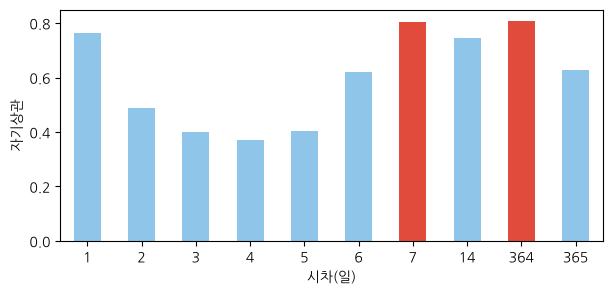

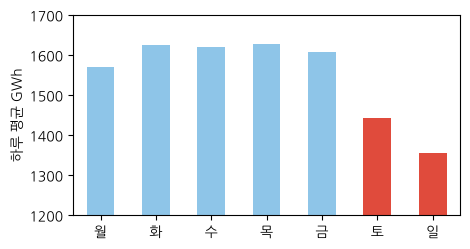

In [35]:
r.plot.bar(color=["#E04B3C" if k in (7, 364) else "#8EC5E8" for k in r.index],
           figsize=(7, 3), rot=0)
plt.xlabel("시차(일)"); plt.ylabel("자기상관"); plt.show()
dow.plot.bar(color=["#8EC5E8"] * 5 + ["#E04B3C"] * 2, figsize=(5, 2.6), rot=0)
plt.ylim(1200, 1700); plt.ylabel("하루 평균 GWh"); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `color=[… for k in r.index]` | 7일과 364일만 빨강으로 칠해 눈에 띄게 한다 |
| `["#8EC5E8"] * 5 + ["#E04B3C"] * 2` | 목록 곱하기와 더하기: 하늘색 다섯, 빨강 둘(주말) |
| `plt.ylim(1200, 1700)` | 세로축 범위를 정한다. 0부터 그리면 요일 차이가 잘 보이지 않는다(대신 축이 0에서 시작하지 않음을 꼭 밝힌다) |



**[결과 읽기]** 기준선 후보는 "어제", "지난주 같은 요일", "작년 같은 요일(364일 전)" 셋이고, 어느 쪽이 나은지는 3.3과 3.7에서 시험으로 가립니다.

> **[직접 해보기]**
>
> ❶ 주말만(`c[c.index.dayofweek >= 5]`) 놓고 평균을 구해 평일 평균과 견주어 보시오. ❶의 13.1%와 같은 값이 나오는가? (확인: 주말 1,400.4, 평일 1,610.9로 13.1% 적다)
>
> ❷ `c.resample("W").mean( ).pct_change( )`로 주마다 평균의 변화율을 구하고 가장 크게 떨어진 주를 찾으시오. 무슨 주인가? (확인: 2023년 10월 1일까지의 주로 −14.9%, 추석 연휴다)

> **[자주 나는 오류]**
>
> 요일 이름이 어긋난다 → 파이썬은 월요일이 0입니다. 엑셀(일요일 1)이나 미국식 달력(일요일 0)과 다릅니다. `c.index[:3].day_name( )`으로 확인합니다.
>
> `ValueError: Length mismatch: Expected axis has 7 elements, new values have 6 elements` → 요일 이름 목록의 길이가 7이 아닙니다.
>
> `autocorr(365)`가 364보다 낮다고 오류는 아니다 → 하루 단위 데이터에서 "1년 전"은 요일이 맞는 364일입니다.

## [실습 예제 12-7 ★] 2025년을 기준선과 프로펫으로 예측하기

2024년까지로 배우고 2025년 365일을 예측하시오. 작년 같은 요일과 두 가지 프로펫을 견주고, 가장 크게 틀린 날의 예측을 부분별로 나누어 보시오(03절 3.3, 3.5).

**❶ 정직한 "작년 같은 요일" 만들기**

In [36]:
# 2024년까지 배우고 2025년 시험
tr_e, te_e = c.loc[:"2024"], c.loc["2025"]
# 2024년의 마지막 52주를 두 번 잇는다
f_364 = np.tile(tr_e.iloc[-364:].values, 2)[:365]
print("2025-01-01은", te_e.index[0].day_name(), "/ 빌려 온 날",
      tr_e.index[-364].date(), tr_e.index[-364].day_name())
# 흔한 실수: 시험 해의 값이 섞인다
leak = c.shift(364).loc["2025"]
print("12월 31일 자리에 들어간 값의 날짜:",
      (te_e.index[-1] - pd.Timedelta(days=364)).date())
print("평균으로 찍기 MAE", mae(te_e, tr_e.loc["2024"].mean()))
print("작년 같은 요일 MAE", mae(te_e, f_364),
      " (shift(364)로 하면", mae(te_e, leak), ")")

2025-01-01은 Wednesday / 빌려 온 날 2024-01-03 Wednesday
12월 31일 자리에 들어간 값의 날짜: 2025-01-01
평균으로 찍기 MAE 156.1
작년 같은 요일 MAE 74.2  (shift(364)로 하면 74.8 )


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `tr_e.iloc[-364:]` | 학습 기간의 마지막 364일(52주). 364는 7의 배수라 요일이 맞는다 |
| `np.tile(…, 2)[:365]` | 52주를 두 번 이어 728일을 만들고 앞 365일만 쓴다 |
| `day_name( )` | 날짜의 요일 이름(영어). 빌려 온 날과 요일이 같은지 확인한다 |
| `c.shift(364).loc["2025"]` | 364일 전 값을 끌어온다. 2025년 12월 31일 자리에는 2025년 1월 1일 값이 온다 |
| `pd.Timedelta(days=364)` | "364일"이라는 시간 길이. 날짜에서 빼면 364일 전 날짜 |


**결과 읽기.** 2025년 1월 1일(수요일)에는 2024년 1월 3일(수요일)의 값을 빌려 씁니다. `shift(364)`로 만들면 12월 31일 자리에 2025년 1월 1일 값이 들어갑니다. 2024년 말에는 알 수 없는 값이니 점수(74.8)는 정직하지 않습니다. 이번에는 우연히 정직한 쪽(74.2)이 조금 더 좋았을 뿐입니다.

> **[자주 하는 실수] 데이터 누수: 시험 답이 학습에 섞인다**
>
> **데이터 누수**(leakage)는 예측하는 순간에는 알 수 없는 정보가 섞이는 것입니다. 흔한 꼴은 셋입니다. ① `shift( )`가 시험 기간의 값을 끌어옴(이 실습의 `shift(364)`), ② 전체 데이터로 표준화나 빈칸 채우기를 한 뒤 나눔(학습 데이터로만 `fit`), ③ 결과가 난 뒤에 생기는 열을 입력으로 씀(연체 예측에 "독촉 문자 횟수"). 점수가 너무 좋으면 먼저 누수를 의심합니다.


> **[잠깐만요] 돈이 걸리면 시각부터 의심하라**
>
> 『데이터 과학 설계 매뉴얼』의 저자 스키나는 뉴스 기사의 감성으로 주가를 예측하는 연구를 한 적이 있습니다. 결과는 좋았지만 그는 끝내 찜찜했다고 털어놓습니다. 기사에 붙은 시각이 정말 시장이 그 기사를 본 시각인지 확신할 수 없었기 때문입니다. 기사 시각이 몇 시간만 이르게 적혀 있어도 모델은 이미 오른 주가를 "예측"한 셈이 됩니다. 시계열에서는 "그때 알 수 있었던 정보인가"를 늘 먼저 묻습니다.

**❷ 프로펫 함수 만들기**

In [37]:
def fit_prophet(series, holidays_on, days=365):
    df = series.reset_index()
    # 프로펫은 열 이름이 ds, y여야 한다
    df.columns = ["ds", "y"]
    m = Prophet(daily_seasonality=False)
    if holidays_on:
        # 한국 공휴일 달력을 알려 준다
        m.add_country_holidays(country_name="KR")
    m.fit(df)
    return m, m.predict(m.make_future_dataframe(periods=days)).set_index("ds")
# 프로펫에 넣을 표의 생김새
print(tr_e.reset_index().set_axis(["ds", "y"], axis=1).head(2))

          ds         y
0 2021-01-01  1448.212
1 2021-01-02  1430.921


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `series.reset_index( )` | 날짜 인덱스를 보통 열로 꺼낸다. 프로펫은 날짜를 열로 받는다 |
| `df.columns = ["ds", "y"]` | 열 이름을 프로펫이 정한 이름으로 바꾼다(날짜 ds, 값 y) |
| `Prophet(daily_seasonality=False)` | 하루 안의 주기는 끈다. 하루에 값이 하나뿐이라 배울 것이 없다 |
| `add_country_holidays(country_name="KR")` | 한국 공휴일을 휴일 효과로 넣는다. 공휴일마다 효과를 따로 배운다 |
| `make_future_dataframe(periods=days)` | 학습 기간 + 그 뒤 days일의 날짜 표 |
| `m.predict( )` | 그 날짜마다 예측 `yhat`, 구간 `yhat_lower`·`yhat_upper`, 부분 `trend`·`weekly`·`yearly`·`holidays`를 채운다 |
| `set_axis([…], axis=1)` | 열 이름을 한 번에 바꾸는 다른 방법(표를 새로 돌려준다) |


**결과 읽기.** 프로펫에 들어가는 것은 날짜 열(ds)과 값 열(y) 두 개뿐입니다. 요일, 한 해의 계절, 휴일 효과는 프로펫이 날짜에서 스스로 만듭니다.

**❸ 두 번 맞추고 채점하기**

In [38]:
m0, fc0 = fit_prophet(tr_e, False)
m1, fc1 = fit_prophet(tr_e, True)
p0, p1 = fc0["yhat"].loc["2025"], fc1["yhat"].loc["2025"]
print("프로펫 기본 MAE", mae(te_e, p0), "/ 프로펫 + 휴일 MAE", mae(te_e, p1))
gain = 1 - mae(te_e, p1) / mae(te_e, f_364)          # 줄어든 비율
print("작년 같은 요일보다", round(gain * 100, 1), "% 작다")
# 2025년 공휴일인 날
hd = te_e.index.isin(pd.to_datetime(list(holidays.KR(years=2025))))
print("공휴일 MAE: 기본", mae(te_e[hd], p0[hd]),
      "→ 휴일", mae(te_e[hd], p1[hd]), f"({hd.sum()}일)")

00:11:08 - cmdstanpy - INFO - Chain [1] start processing


00:11:09 - cmdstanpy - INFO - Chain [1] done processing


00:11:09 - cmdstanpy - INFO - Chain [1] start processing


00:11:09 - cmdstanpy - INFO - Chain [1] done processing


프로펫 기본 MAE 70.3 / 프로펫 + 휴일 MAE 58.8
작년 같은 요일보다 20.8 % 작다
공휴일 MAE: 기본 230.7 → 휴일 92.5 (19일)


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `m0, fc0 = fit_prophet(…)` | 함수가 돌려준 두 값(모델, 예측 표)을 두 이름에 나누어 받는다 |
| `fc1["yhat"].loc["2025"]` | 예측 표에는 학습 기간도 들어 있으므로 2025년만 꺼낸다 |
| `holidays.KR(years=2025)` | 2025년 한국 공휴일 사전(날짜: 이름). 대체 휴일과 임시 공휴일도 들어 있다 |
| `index.isin( )` | 날짜마다 "목록에 있나"를 참·거짓으로. `te_e[hd]`는 참인 날만 |


**결과 읽기.** 휴일을 알려 주자 MAE가 70.3에서 58.8로 줄었고, 줄어든 몫의 절반 넘게가 공휴일 19일에서 나왔습니다(공휴일 MAE 230.7 → 92.5). 작년 같은 요일보다 20.8% 작게 틀립니다([표 12-2]와 같은 값).

## [코랩 실습] 12-7 더 하기: 가장 크게 틀린 날을 부분으로 나누어 보기

**❶ 가장 크게 틀린 날을 부분으로 나누어 보기**

In [39]:
err = (te_e - p1).abs().sort_values(ascending=False)   # 틀린 크기를 큰 것부터
print("크게 틀린 날:", [str(d.date()) for d in err.index[:3]])
d0 = err.index[0]
print(d0.date(), d0.day_name(), "실제", round(te_e[d0], 1))
parts = ["trend", "weekly", "yearly", "holidays", "yhat"]
print(fc1.loc[d0, parts].round(1).to_string())

크게 틀린 날: ['2025-10-05', '2025-10-09', '2025-08-25']
2025-10-05 Sunday 실제 1210.1
trend       1558.2
weekly      -196.2
yearly      -121.7
holidays    -341.2
yhat         899.2


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `(te_e - p1).abs( )` | 날마다 틀린 크기(부호 없이) |
| `sort_values(ascending=False)` | 큰 것부터 늘어놓는다. 위의 몇 날이 오차 분석의 출발점 |
| `fc1.loc[d0, [ … ]]` | 그날 예측을 이룬 부분들. `yhat` = 추세 + 요일 + 한 해의 계절 + 휴일 |


**결과 읽기.** 크게 틀린 세 날 가운데 둘이 2025년 추석 연휴(10월 3~9일)입니다. 10월 5일은 일요일 효과(−196.2)와 추석 전날 효과(−341.2)를 둘 다 빼서 899.2로 예측했지만, 실제는 1,210.1이었습니다. 더하기만 하는 모델은 일요일과 휴일이 겹친 날을 두 번 깎습니다(3.5).

> **[분석 기법] 가장 크게 틀린 것부터 본다**
>
> 평균 오차 하나로는 어디서 틀리는지 모릅니다. 오차 크기를 `abs( )`로 구해 `sort_values(ascending=False)`로 늘어놓고 위에서 몇 개를 직접 들여다봅니다(**오차 분석**). 여기서는 위의 날들이 모두 2025년 추석 연휴에 몰려 있었고, 답은 "효과를 더하기만 하는 모델은 겹친 날을 모른다"였습니다. 집값 모델이면 크게 틀린 집이 신축인지 보는 식으로, 다음에 고칠 곳은 대개 여기서 나옵니다.




**❹ 10월 한 달 그래프**

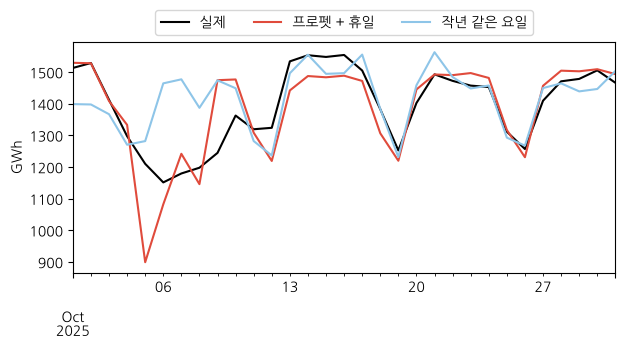

In [40]:
oct25 = slice("2025-10-01", "2025-10-31")
te_e[oct25].plot(color="black", label="실제", figsize=(7, 3))
p1[oct25].plot(color="#E04B3C", label="프로펫 + 휴일")
# 배열에 2025년 날짜를 붙인다
sn25 = pd.Series(f_364, te_e.index)
sn25[oct25].plot(color="#8EC5E8", label="작년 같은 요일")
# 범례는 그래프 위에
plt.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1))
plt.ylabel("GWh"); plt.xlabel(""); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `slice("2025-10-01", "2025-10-31")` | 기간 하나를 이름 붙여 두고 여러 번 쓴다. `te_e["2025-10"]`과 같은 범위 |
| `pd.Series(f_364, te_e.index)` | 날짜가 없는 배열에 2025년 날짜를 붙여 시리즈로 만든다 |
| `.plot( )`을 세 번 | 같은 판에 차례로 겹쳐 그린다 |


**[결과 읽기]** 작년 같은 요일(하늘색)은 2024년 추석이 9월이어서 10월 연휴를 통째로 놓쳤고, 프로펫(빨강)은 연휴는 알지만 깊이를 틀렸습니다. 두 방법이 서로 다르게 틀린다는 점이 실습 예제 12-8의 결합 예측으로 이어집니다.

> **[직접 해보기]**
>
> ❶ `m1.plot_components(fc1)`를 실행해 프로펫이 배운 추세, 요일, 한 해의 계절, 휴일 효과를 그림으로 보시오. 요일 효과가 가장 낮은 요일은? (확인: 일요일)
>
> ❷ 휴일을 넣은 프로펫의 95% 구간(`yhat_lower`, `yhat_upper`) 안에 2025년 실제 값이 며칠 들었는지 세어 보시오. (확인: 365일 가운데 280일, 76.7%. 95%보다 훨씬 적으니 구간이 지나치게 좁다. 6.3의 점검법이다)

> **[자주 나는 오류]**
>
> `ValueError: Dataframe must have columns "ds" and "y"` → 열 이름이 날짜, 값처럼 그대로입니다. `df.columns = ["ds", "y"]`를 빠뜨렸는지 봅니다.
>
> `Exception: Prophet object can only be fit once` → 한 번 맞춘 모델을 다시 `fit( )`했습니다. 새로 맞출 때마다 `Prophet( )`을 새로 만듭니다. 함수로 싸 둔 까닭입니다.
>
> 출력에 `cmdstanpy - INFO` 줄이 잔뜩 나온다 → 계산 과정 알림이라 무시해도 됩니다. 노트북 첫 칸의 `logging` 설정이 이를 숨깁니다.

## [실습 예제 12-8 ★] 해마다 기준점을 옮겨 전력 수요 예측하기

2023~2025년을 해마다 그 전해까지로 배워 예측하고, 작년 같은 요일, 프로펫, 둘의 평균을 견주시오(03절 3.6). 프로펫을 세 번 맞추므로 1분쯤 걸립니다.

**❶ 기준점을 한 해씩 옮기며 예측하기**

In [41]:
rows, keep = [], {}
# 2023~2025년을 차례로 시험
for Y in range(2023, 2026):
    # 그 전해까지 학습, 그해 시험
    tr, te = c.loc[:str(Y - 1)], c.loc[str(Y)]
    # 작년 같은 요일 (시험 해 값은 쓰지 않음)
    sn = np.tile(tr.iloc[-364:].values, 2)[:len(te)]
    p = fit_prophet(tr, True, len(te))[1]["yhat"].loc[str(Y)].values
    # 뒤에서 다시 보려고 넣어 둔다
    keep[Y] = (te, sn, p)
    rows.append({"시험 해": Y, "배운 해 수": Y - 2021,
                 "작년 같은 요일": mae(te, sn), "프로펫+휴일": mae(te, p),
                 "둘의 평균": mae(te, (sn + p) / 2)})
    print(Y, "끝: 학습", len(tr), "일 / 시험", len(te), "일")

00:11:10 - cmdstanpy - INFO - Chain [1] start processing


00:11:10 - cmdstanpy - INFO - Chain [1] done processing


00:11:10 - cmdstanpy - INFO - Chain [1] start processing


00:11:10 - cmdstanpy - INFO - Chain [1] done processing


2023 끝: 학습 730 일 / 시험 365 일


00:11:11 - cmdstanpy - INFO - Chain [1] start processing


2024 끝: 학습 1095 일 / 시험 366 일


00:11:11 - cmdstanpy - INFO - Chain [1] done processing


2025 끝: 학습 1461 일 / 시험 365 일


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `c.loc[:str(Y - 1)]`, `c.loc[str(Y)]` | 실습 예제 12-4와 같은 틀. 그 전해 끝까지 배우고 그해를 시험한다 |
| `[:len(te)]` | 시험 해의 날 수만큼 자른다. 2024년은 윤년이라 366일 |
| `fit_prophet(tr, True, len(te))[1]` | 함수가 돌려준 (모델, 예측 표) 가운데 둘째(예측 표)만 |
| `keep[Y] = (te, sn, p)` | 해마다 실제와 두 예측을 사전에 넣어 둔다. ❸에서 다시 쓴다 |
| `(sn + p) / 2` | 결합 예측 |
| `print(Y, "끝: …")` | 오래 걸리는 반복은 한 바퀴마다 진행을 찍어 두면 멈춘 것인지 아닌지 안다 |


**결과 읽기.** 학습 기간이 해마다 한 해씩 늘어납니다(730 → 1,095 → 1,461일). 2024년만 366일을 시험했습니다.

**❷ 성적표로 모으기**

In [42]:
eroll = pd.DataFrame(rows).set_index("시험 해")      # 사전의 목록 → 표
print(eroll.to_string())
print(eroll.iloc[:, 1:].agg(["mean", "max"]).round(1).to_string())

      배운 해 수  작년 같은 요일  프로펫+휴일  둘의 평균
시험 해                                 
2023       2      72.4   121.9   80.7
2024       3      81.8    66.6   68.2
2025       4      74.2    58.8   60.1
      작년 같은 요일  프로펫+휴일  둘의 평균
mean      76.1    82.4   69.7
max       81.8   121.9   80.7


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `pd.DataFrame(rows)` | 사전 하나가 한 줄, 키가 열 이름이 된다 |
| `eroll.iloc[:, 1:]` | 모든 줄, 둘째 열부터(점수 열만). "배운 해 수"는 뺀다 |
| `.agg(["mean", "max"])` | 열마다 평균과 가장 큰 값(가장 나빴던 해)을 한 번에 |


**결과 읽기.** 해마다 값은 [표 12-3]과 같습니다. 프로펫은 배운 해가 셋, 넷으로 늘자 기준선을 이겼지만, 두 해로만 배운 2023년에는 크게 졌습니다. 평균은 둘의 평균(69.7)이 가장 작고, 가장 나빴던 해(80.7)도 다른 둘의 최악(81.8, 121.9)보다 낫습니다.

> **[분석 기법] 성적표는 평균과 최악을 함께 본다**
>
> 여러 번 시험한 성적표에서는 평균만이 아니라 가장 나빴던 때(`max`)도 봅니다. 평균이 비슷하면 크게 망한 해가 적은 쪽이 쓰기 안전합니다. `표.agg(["mean", "max"])` 한 줄로 둘을 함께 구합니다.
>
> 모든 방법이 함께 크게 틀린 해(여기서는 2023년의 프로펫)는 모델의 탓이 아니라 데이터에 무슨 일이 있었다는 신호입니다. 이런 해를 빼고도 결론이 같은지 확인합니다.


**❸ 왜 둘의 평균이 강한가: 틀리는 방향 보기**

In [43]:
for Y, (te, sn, p) in keep.items():
    # 실제 − 예측 (양수면 낮게 예측)
    e_sn, e_p = te.values - sn, te.values - p
    # 두 오차의 부호가 다른 날의 비율
    opp = (np.sign(e_sn) != np.sign(e_p)).mean()
    print(Y, "서로 반대로 틀린 날", round(opp * 100, 1), "% / 두 오차의 상관",
          round(np.corrcoef(e_sn, e_p)[0, 1], 2))

2023 서로 반대로 틀린 날 43.8 % / 두 오차의 상관 0.2
2024 서로 반대로 틀린 날 19.7 % / 두 오차의 상관 0.59
2025 서로 반대로 틀린 날 28.8 % / 두 오차의 상관 0.55


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `for Y, (te, sn, p) in keep.items( )` | 사전에서 해와 (실제, 예측, 예측) 묶음을 한꺼번에 풀어 받는다 |
| `te.values - sn` | 실제 − 예측. 양수면 낮게, 음수면 높게 예측한 날 |
| `np.sign( )` | 양수는 1, 음수는 −1, 0은 0 |
| `( … != … ).mean( )` | 참·거짓의 평균 = 참의 비율 |
| `np.corrcoef(a, b)[0, 1]` | 두 줄의 상관계수(2 × 2 표의 오른쪽 위 칸) |


**결과 읽기.** 해마다 열흘에 두~네 날(20~44%)은 두 방법이 서로 반대쪽으로 틀렸고, 두 오차의 상관도 0.2~0.59로 1보다 한참 작습니다. 프로펫이 크게 진 2023년에 서로 반대로 틀린 날이 가장 많아, 평균이 프로펫(121.9)을 크게 건졌습니다. 이런 날은 평균하면 오차가 서로 깎입니다. 두 방법이 늘 같은 쪽으로 틀린다면(상관이 1에 가까우면) 평균해도 나아지지 않습니다.

**❹ 해마다 성적 그래프**

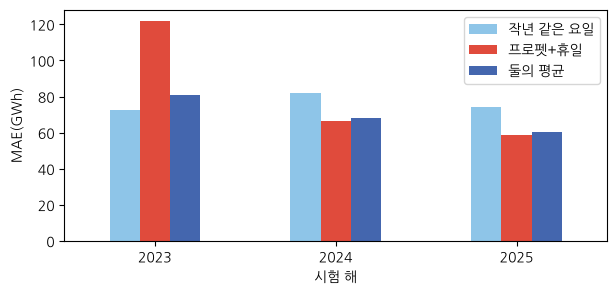

In [44]:
eroll.iloc[:, 1:].plot.bar(color=["#8EC5E8", "#E04B3C", "#4466AE"],
                           figsize=(7, 3), rot=0)
plt.ylabel("MAE(GWh)"); plt.xlabel("시험 해"); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `표.plot.bar( )` | 열이 여럿인 표는 줄(해)마다 열(방법) 막대를 나란히 그린다 |
| `color=[…]` | 열의 순서대로 색을 준다 |


**[결과 읽기]** 한 해만 시험했다면 2023년이면 "프로펫은 쓸모없다", 2025년이면 "기준선은 쓸모없다"는 서로 반대의 결론을 냈을 것입니다. 여러 번 시험하면 결론이 운에 덜 흔들립니다.

> **[직접 해보기]**
>
> ❶ 결합 예측의 무게를 0.5 대신 프로펫 0.7, 기준선 0.3으로 바꾸면 세 해 평균 MAE는? (확인: 72.8로 오히려 나빠진다. 무게를 시험 성적으로 고르면 누수이니, 고르려면 학습 기간 안에서 고른다)
>
> ❷ 시험 해를 2022년부터(`range(2022, 2026)`) 시작하면 프로펫은 한 해로만 배웁니다. 2022년 프로펫 MAE는? (확인: 926.0으로 무너진다. 한 해짜리 데이터로는 한 해의 계절과 추세를 가를 수 없어서다. 한 해의 계절을 배우려면 적어도 두 해가 필요하다)

> **[자주 나는 오류]**
>
> `ValueError: operands could not be broadcast together with shapes (366,) (365,)` → 윤년을 잊고 365일로 고정했습니다. `len(te)`를 씁니다.
>
> 표에 줄이 하나뿐이다 → `rows.append( )`가 `for` 안으로 들여쓰기 되지 않아 마지막 해만 남았습니다.

## [알고리즘 따라 하기 12-9] 여드레 판매로 지연 특징과 나무 하나 익히기

날이 더워진 한 주, 아이스크림 판매(십 개)가 10, 11, 13, 12, 20, 21, 23, 22였습니다. "어제 판매" 특징을 만들고, 질문 하나짜리 나무와 나무 세 그루짜리 숲이 다음 날을 어떻게 예측하는지 보시오.

**❶ shift로 "어제" 열 만들기**

In [45]:
v8 = pd.Series([10, 11, 13, 12, 20, 21, 23, 22], dtype=float,
               index=pd.date_range("2025-03-03", periods=8))
lag = pd.DataFrame({"어제": v8.shift(1), "오늘": v8}).dropna()
lag.index = lag.index.strftime("%d일")              # 날짜를 짧게
print(lag.T.astype(int).to_string())

    04일  05일  06일  07일  08일  09일  10일
어제   10   11   13   12   20   21   23
오늘   11   13   12   20   21   23   22


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `v8.shift(1)` | 값을 한 칸 뒤로 밀어, 오늘 줄에 어제 값이 오게 한다 |
| `.dropna( )` | 어제가 없는 첫날 줄을 버린다. 여덟 날에서 일곱 줄이 남는다 |
| `strftime("%d일")` | 날짜를 "04일"처럼 짧은 글자로 바꾼다 |
| `lag.T` | 가로세로를 바꿔(전치) 한 화면에 보이게 한다 |


**결과 읽기.** 4일 칸은 "어제 10 → 오늘 11"입니다. 이제 시계열 문제가 "어제를 보고 오늘을 맞히는" 보통의 회귀 표가 되었습니다.

**❷ 나무 하나는 질문 하나로 나눈다**

In [46]:
from sklearn.tree import DecisionTreeRegressor, export_text
tree1 = DecisionTreeRegressor(max_depth=1)          # 질문 한 번만
tree1.fit(lag[["어제"]], lag["오늘"])
print(export_text(tree1, feature_names=["어제"]))

|--- 어제 <= 16.50
|   |--- value: [14.00]
|--- 어제 >  16.50
|   |--- value: [22.00]



**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `max_depth=1` | 나무의 깊이를 1로, 곧 질문을 한 번만 하게 한다 |
| `lag[["어제"]]` | 대괄호 두 겹: 열 하나짜리 표(특징 X). 한 겹이면 시리즈가 된다 |
| `export_text( )` | 나무가 배운 질문과 잎의 예측값을 글로 보여 준다 |


**[손 계산]**

| 잎 | 들어간 날의 오늘 값 | 평균 = 예측 |
|---|---|---|
| 어제 ≤ 16.5 | 11, 13, 12, 20 | 56 ÷ 4 = 14 |
| 어제 > 16.5 | 21, 23, 22 | 66 ÷ 3 = 22 |

**결과 읽기.** 나무는 가능한 모든 자르기를 해 보고, 양쪽 잎 안에서 "평균에서 벗어난 크기의 제곱 합"이 가장 작은 자리(어제 12와 20의 한가운데 16.5)를 골랐습니다. 예측은 그 잎에 든 날들의 평균일 뿐입니다.

**❸ 나무 세 그루의 평균이 숲이다**

In [47]:
forest = RandomForestRegressor(n_estimators=3, max_depth=1, random_state=0)
forest.fit(lag[["어제"]], lag["오늘"])
x_new = pd.DataFrame({"어제": [22.0]})               # 오늘이 22면 내일은?
each = [float(t.predict(x_new.values)[0]) for t in forest.estimators_]
print("나무마다:", [round(e, 1) for e in each], "→ 평균", round(np.mean(each), 2),
      "/ 숲:", round(forest.predict(x_new)[0], 2))

나무마다: [21.5, 21.0, 22.2] → 평균 21.57 / 숲: 21.57


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `n_estimators=3` | 나무를 세 그루 심는다. 나무마다 일곱 줄에서 뽑기를 되풀이한(중복 허용) 다른 표로 배운다 |
| `forest.estimators_` | 다 배운 나무 하나하나의 목록 |
| `x_new.values` | 낱낱의 나무는 열 이름 없이 배웠으므로 값만 넘긴다 |
| `forest.predict( )` | 세 나무의 예측을 평균한 값 |


**결과 읽기.** 나무마다 본 표가 달라 예측이 조금씩 다르고, 숲은 그 평균을 냅니다. 한 나무가 우연히 치우쳐도 평균하면 덜 흔들립니다. 실습 예제 12-9는 같은 일을 특징 8개, 1,400여 줄, 나무 300그루로 합니다.

## [실습 예제 12-9 ★] 지연 특징으로 다음 날 예측하기

지연 특징과 달력 특징으로 랜덤 포레스트를 배우게 하고, 2025년의 매일 다음 날을 예측하시오(03절 3.7).

**❶ 휴일 열 만들기**

In [48]:
# 한국 공휴일(설·추석 연휴, 대체 휴일 포함)
kr = holidays.KR(years=range(2021, 2026))
hol = pd.Series([d in kr for d in c.index.date], index=c.index).astype(int)
print("다섯 해 공휴일", hol.sum(), "일 / 2025년", hol.loc["2025"].sum(), "일")
week = hol.loc["2025-10-02":"2025-10-10"]
print("10월 2~10일:", " ".join(f"{d.day}일={v}" for d, v in week.items()))
print("10월 6일 이름:", kr.get("2025-10-06"))

다섯 해 공휴일 93 일 / 2025년 19 일
10월 2~10일: 2일=0 3일=1 4일=0 5일=1 6일=1 7일=1 8일=1 9일=1 10일=0
10월 6일 이름: 추석


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `holidays.KR(years=range(2021, 2026))` | 2021~2025년 한국 공휴일 사전. `날짜 in kr`로 공휴일인지 묻는다 |
| `[d in kr for d in c.index.date]` | 날짜마다 참·거짓을 담은 목록(한 줄짜리 반복) |
| `pd.Series(목록, index=c.index)` | 그 목록에 날짜를 붙여 c와 줄을 맞춘다 |
| `.astype(int)` | 참·거짓을 1·0으로. 모델은 숫자만 받는다(8장의 더미 변수) |
| `f"{d.day}일={v}"` | 날짜의 일과 값을 "3일=1" 꼴로. `" ".join( )`이 그것들을 빈칸으로 잇는다 |
| `kr.get(날짜)` | 그날 공휴일의 이름(공휴일이 아니면 None) |


**결과 읽기.** 2025년 추석 연휴는 개천절(3일)부터 한글날(9일)까지 이레가 내리 쉬는 날입니다. 4일(토)은 공휴일 달력에 없어 0이지만 주말이라 요일 열이 알려 주고, 5일(일)은 추석 연휴의 첫날이라 1입니다.

**❷ 지연 특징 표 만들기**

In [49]:
X = pd.DataFrame({"어제": c.shift(1), "지난주 같은 요일": c.shift(7),
                  "작년 같은 요일": c.shift(364),
                  "지난 7일 평균": c.shift(1).rolling(7).mean(),
                  "달": c.index.month, "요일": c.index.dayofweek,
                  "휴일": hol, "어제가 휴일": hol.shift(1, fill_value=0)})
# 정답 열을 붙이고 빈칸 줄을 버린다
data = X.join(c.rename("y")).dropna()
print(data.shape, "/ 첫 날", data.index[0].date())
print(data.loc["2025-10-06"].round(1).to_string())

(1462, 9) / 첫 날 2021-12-31
어제           1210.1
지난주 같은 요일    1505.2
작년 같은 요일     1464.4
지난 7일 평균     1429.4
달              10.0
요일              0.0
휴일              1.0
어제가 휴일          1.0
y            1151.4


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `c.shift(1)`, `c.shift(7)`, `c.shift(364)` | 어제, 지난주 같은 요일, 작년 같은 요일의 값을 오늘 줄로 끌어온다 |
| `c.shift(1).rolling(7).mean( )` | 어제까지 7일의 평균. `shift(1)`을 먼저 해야 오늘 값이 섞이지 않는다 |
| `hol.shift(1, fill_value=0)` | 어제가 휴일이었나. 맨 앞 빈칸은 0으로 채운다 |
| `X.join(c.rename("y"))` | 같은 날짜끼리 옆으로 붙인다. 정답 열 이름은 y |
| `.dropna( )` | 지연 때문에 앞쪽에 생긴 빈칸 줄(364일 + 1)을 버린다 |
| `data.loc["2025-10-06"]` | 한 날의 특징 줄을 세로로 본다. 모델이 그날 보는 것이 이것뿐이다 |


**결과 읽기.** 앞쪽 364일은 "작년 같은 요일"이 없어 버려져, 2021년 12월 31일부터 1,462일이 남았습니다. 추석 당일(10월 6일)의 줄을 보면 모델은 어제(일요일, 추석 전날)의 낮은 값과 지난주 월요일의 높은 값, "휴일 = 1"을 함께 받습니다.

> **[분석 기법] 날짜 하나에서 특징 여럿 뽑기**
>
> 날짜 열 하나에서 머신러닝 모델이 쓸 특징을 여럿 만들 수 있습니다. 달력 특징(달 `index.month`, 요일 `index.dayofweek`, 주말·휴일 여부), 지연 특징(`shift(1)`, `shift(7)`), 최근 통계(`shift(1).rolling(7).mean( )`)입니다.
>
> 배달 주문, 매장 방문, 앱 접속처럼 날짜가 붙은 데이터라면 어디든 이 목록에서 시작합니다. 모델이 날짜 자체를 이해하지는 못하므로, 사람이 아는 달력 지식을 열로 풀어 주는 것입니다(**특징 공학**).


**❸ 나누고, 기준선 채점하기**

In [50]:
trB, teB = data.loc[:"2024"], data.loc["2025"]
# 정답(y)을 뺀 나머지가 입력
feats = [k for k in data.columns if k != "y"]
print("입력 특징", len(feats), "개:", feats)
print("배운 날", len(trB), "/ 시험 날", len(teB))
print("어제 값 MAE", mae(teB.y, teB["어제"]), "/ 지난주 같은 요일 MAE",
      mae(teB.y, teB["지난주 같은 요일"]),
      "/ 작년 같은 요일 MAE", mae(teB.y, teB["작년 같은 요일"]))

입력 특징 8 개: ['어제', '지난주 같은 요일', '작년 같은 요일', '지난 7일 평균', '달', '요일', '휴일', '어제가 휴일']
배운 날 1097 / 시험 날 365
어제 값 MAE 94.5 / 지난주 같은 요일 MAE 92.3 / 작년 같은 요일 MAE 74.8


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `[k for k in data.columns if k != "y"]` | 조건이 붙은 한 줄 반복: y가 아닌 열 이름만 모은다 |
| `teB.y` | `teB["y"]`의 줄임. 열 이름이 영어 한 단어일 때만 된다 |
| `teB["어제"]` | 지연 특징 열이 그대로 기준선 예측이다. "어제 값" 예측 = 어제 열 |


**결과 읽기.** 다음 날을 맞히는 데에서는 어제(94.5)와 지난주(92.3)가 거의 비깁니다. 실습 예제 12-6의 자기상관(0.765, 0.802)이 그대로 드러납니다. 셋 가운데에서는 작년 같은 요일(74.8)이 가장 낫습니다. 실습 예제 12-7에서 누수라고 했던 `shift(364)`와 같은 값인데, 다음 날 예측에서는 364일 전 값을 그날 밤에 이미 알고 있으니 정직한 특징입니다. 같은 `shift`도 언제 예측하느냐에 따라 누수가 되기도 하고 아니기도 합니다.

**❹ 랜덤 포레스트로 배우고 채점하기**

In [51]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                           random_state=0, n_jobs=-1)
rf.fit(trB[feats], trB.y)                           # 2024년까지로 배운다
pred = rf.predict(teB[feats])                       # 2025년 매일의 다음 날
score_rf = mae(teB.y, pred)
print("랜덤 포레스트 MAE", score_rf, "/ 하루 수요의",
      round(score_rf / teB.y.mean() * 100, 1), "%")
bases = ["어제", "지난주 같은 요일", "작년 같은 요일"]
best = min(mae(teB.y,
               teB[k]) for k in bases)      # 세 기준선 가운데 가장 작은 MAE
print("가장 좋은 기준선(", best, ")보다", round((1 - score_rf / best) * 100,
                                       1), "% 작다")

랜덤 포레스트 MAE 43.1 / 하루 수요의 2.8 %
가장 좋은 기준선( 74.8 )보다 42.4 % 작다


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `RandomForestRegressor(…)` | 10장의 랜덤 포레스트, 수치 예측판. 괄호 안의 설정은 아래 상자 |
| `rf.fit(입력 표, 정답)` | 2024년까지의 줄로 배운다. 입력은 표, 정답은 한 줄 |
| `rf.predict(teB[feats])` | 2025년 줄마다 예측. 그날의 특징은 모두 전날 밤에 알던 값이다 |


**결과 읽기.** 랜덤 포레스트(43.1 GWh)는 하루 수요의 2.8%만 틀리고, 가장 좋은 기준선(74.8)보다 40% 넘게 작게 틀립니다. 어제(94.5)와 지난주(92.3)에 견주면 절반 아래입니다.

> **[잠깐만요] 모델을 만들 때 정하는 값: 하이퍼파라미터**
>
> 학습으로 정해지지 않고 사람이 미리 정하는 값을 **하이퍼파라미터**라 합니다. `n_estimators`는 나무 수(많을수록 안정, 대신 느림), `min_samples_leaf`는 잎에 남길 최소 날 수(크면 덜 외움)입니다. `random_state=0`은 무작위의 출발점을 고정해 누가 돌려도 같은 결과를 내고(**재현성**), `n_jobs=-1`은 모든 코어를 씁니다. 고를 때는 시험 데이터가 아니라 학습 기간 안의 검증으로 고릅니다.


## [코랩 실습] 12-9 더 하기: 요일별로 오차 나누어 보기

**❶ 요일별로 오차 나누어 보기**

In [52]:
week_ago = teB["지난주 같은 요일"]
er = pd.DataFrame({"어제 값": (teB.y - teB["어제"]).abs(),
                   "지난주 같은 요일": (teB.y - week_ago).abs(),
                   "랜덤 포레스트": np.abs(teB.y - pred)})
# 0~6 → 월~일
er.index = teB.index.dayofweek.map(dict(enumerate("월화수목금토일")))
er.index.name = "요일"
# 요일로 묶어 평균 내고 월~일 순서로 세운다
by_day = er.groupby(level=0).mean().reindex(list("월화수목금토일"))
print(by_day.round(1).to_string())

     어제 값  지난주 같은 요일  랜덤 포레스트
요일                           
월   218.1      102.0     53.4
화    62.6      110.9     51.0
수    40.6      110.8     43.6
목    38.8       98.5     36.6
금    55.8       94.4     47.0
토   153.6       60.7     31.9
일    93.1       68.7     38.3


**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `(teB.y - teB["어제"]).abs( )` | 날마다 "어제 값" 예측의 틀린 크기 |
| `dict(enumerate("월화수목금토일"))` | {0: "월", 1: "화", …}. 글자 하나하나에 번호를 붙여 사전으로 |
| `.map(사전)` | 요일 번호를 사전대로 요일 글자로 바꾼다 |
| `groupby(level=0)` | 줄 이름(요일)으로 묶는다 |
| `.reindex(list("월화수목금토일"))` | 줄을 월~일 순서로 다시 세운다 |


**결과 읽기.** "어제 값"은 월요일(일요일 값을 베낌, 218.1)과 토요일(금요일 값을 베낌, 153.6)에 크게 틀리고, 화~금에는 지난주 같은 요일보다 훨씬 낫습니다(01절). 랜덤 포레스트는 두 열을 함께 보고 요일과 휴일로 어느 쪽을 믿을지 골라, 월요일 오차를 53.4로 줄였습니다. 수요일만 어제 값(40.6)이 조금 낫습니다.



**❺ 특징 중요도 그래프**

{'지난주 같은 요일': 0.512, '작년 같은 요일': 0.218, '어제': 0.135}


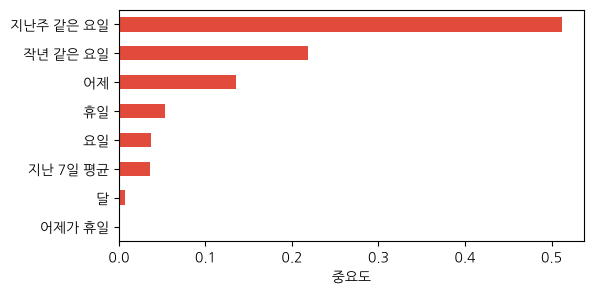

In [53]:
imp = pd.Series(rf.feature_importances_, feats).sort_values()   # 기여한 몫
print(imp.sort_values(ascending=False).round(3).head(3).to_dict())
imp.plot.barh(color="#E04B3C", figsize=(6, 3))
plt.xlabel("중요도"); plt.show()

**[줄별 읽기]**

| 코드 | 하는 일 |
|---|---|
| `rf.feature_importances_` | 특징마다 나무가 갈라질 때 오차를 줄인 몫. 모두 더하면 1 |
| `pd.Series(값, feats)` | 몫에 특징 이름을 붙인다 |
| `.sort_values( )` | 작은 것부터. 가로 막대에서는 큰 것이 맨 위에 온다 |



**[결과 읽기]** 지난주 같은 요일이 절반 가까이를 차지합니다. 하지만 모델이 지난주 값만 쓰는 것은 아닙니다(코랩 실습의 요일별 오차). 요일과 휴일 열은 몫이 작아도 "어느 날 무엇을 믿을지"를 가르는 데 쓰입니다.

> **[분석 기법] 특징 중요도를 읽을 때 주의할 점**
>
> `feature_importances_`는 나무가 갈라질 때 특징마다 오차를 줄인 몫입니다. 첫째, 닮은 특징끼리는 몫을 나눠 갖습니다. 둘째, 중요도는 원인이 아닙니다. 지난주 값이 전기를 쓰는 것이 아니라 사람들의 일과를 대신 알려 줄 뿐입니다. 시험 데이터에서 특징을 하나씩 섞어 보는 `permutation_importance( )`가 더 믿을 만합니다.


> **[직접 해보기]**
>
> ❶ 특징에서 "휴일"과 "어제가 휴일"을 빼고 다시 배우게 하면 MAE는 얼마나 나빠지는가? (확인: 46.7. 공휴일 달력 두 열이 오차를 8%쯤 줄인다)
>
> ❷ 일부러 누수를 만들어 보시오. 특징에 `c.rolling(7).mean( )`(`shift` 없음)을 더하면 MAE는? (확인: 40.4로 좋아진다. 맞힐 날의 값이 7분의 1만 섞여도 점수가 좋아지지만, 실제로는 내일 값을 모르므로 쓸 수 없는 점수다)

> **[자주 나는 오류]**
>
> `ValueError: Input X contains NaN` → `dropna( )`를 빠뜨렸습니다. 지연 특징의 앞쪽은 늘 비어 있습니다.
>
> `ValueError: The feature names should match those that were passed during fit` → 배울 때와 예측할 때 특징 열의 이름이나 순서가 다릅니다. 둘 다 `[feats]`로 고릅니다.
>
> `KeyError: 'y'` → 정답 열 이름을 붙이지 않았습니다. `c.rename("y")`로 이름을 준 뒤 `join`합니다.

> **핵심 3줄**
>
> 날짜를 인덱스로 읽고, `groupby`·`resample`·`rolling`으로 묶고, `shift`·`autocorr`로 밀고 잽니다.
>
> 날짜로 나누고, 같은 `mae( )`로 기준선과 모델을 채점하며, 기준점을 옮겨 되풀이합니다.
>
> 특징은 그때 알던 값(`shift(1)` 이상)으로만 만들고, 가장 크게 틀린 것부터 들여다봅니다.

# [미니 프로젝트 12] 독일 전력으로, 한국 데이터에서 못 본 것 겪어 보기

**질문.** 한국 데이터는 다섯 해, 빈칸이 없고, 재는 방법도 한 번도 바뀌지 않은 깨끗한 데이터였습니다. 실제 데이터는 그렇지 않을 때가 많습니다. 독일의 열두 해 전력 수요로 한국 데이터에서는 겪을 수 없었던 네 가지, 곧 측정을 늦게 시작한 열, 계단처럼 뛴 해, 처음 오는 휴일, 긴 기록을 겪어 보시오.

**데이터.** 독일 전체의 하루 전력 소비량(GWh) 2006~2017년 4,383일로, 송전망에서 잰 부하를 공개 데이터 프로젝트 OPSD가 정리한 것입니다. 풍력, 태양광 발전량 열도 있습니다. 인터넷 주소에서 바로 읽습니다.

**0단계: 읽기**

In [54]:
URL_EL = ("https://raw.githubusercontent.com/jenfly/opsd/"
          "master/opsd_germany_daily.csv")
el = pd.read_csv(URL_EL, parse_dates=["Date"], index_col="Date").asfreq("D")
g = el["Consumption"]                               # 하루 전력 소비, 단위 GWh
print(el.shape, "/", el.index[0].date(), "~", el.index[-1].date())
print(el.columns.tolist())

(4383, 4) / 2006-01-01 ~ 2017-12-31
['Consumption', 'Wind', 'Solar', 'Wind+Solar']


**1단계: 늦게 시작한 열**([실습 예제 12-5] 응용). 열마다 빈칸 수와 첫 값이 있는 날(`first_valid_index( )`)을 구하고, 빈칸을 채울지 열을 버릴지 기간을 자를지 정하시오.

In [55]:
print("빈칸:", el.isna().sum().to_dict())
print("첫 값이 있는 날:",
      {k: str(el[k].first_valid_index().date()) for k in el.columns})

빈칸: {'Consumption': 0, 'Wind': 1463, 'Solar': 2195, 'Wind+Solar': 2196}
첫 값이 있는 날: {'Consumption': '2006-01-01', 'Wind': '2010-01-01', 'Solar': '2012-01-01', 'Wind+Solar': '2012-01-01'}


빈칸이 "측정을 시작하기 전"에만 몰려 있는지, 중간에 띄엄띄엄 있는지를 먼저 가립니다. 앞의 것이면 채우지 않고 기간을 자르거나 열을 버립니다.

**2단계: 계단 찾기**([실습 예제 12-5] 응용). 해마다 평균의 변화율(`pct_change( )`)과 2014년의 달마다 전년 같은 달 대비 변화를 구하고, 세상이 바뀐 것인지 재는 방법이 바뀐 것인지 판단하시오.

In [56]:
gy = g.groupby(g.index.year).mean()                 # 해마다 하루 평균
print("전년 대비 변화(%):",
      (gy.pct_change() * 100).round(1).loc[2009:2015].to_dict())
gm = g.resample("MS").mean()                        # 달마다 평균
ratio = (gm.loc["2014"].values / gm.loc["2013"].values - 1) * 100
print("2014년 달마다 전년 같은 달 대비(%):", np.round(ratio, 1))

전년 대비 변화(%): {2009: -7.0, 2010: 6.3, 2011: -0.8, 2012: -3.4, 2013: -1.1, 2014: 8.8, 2015: 0.2}
2014년 달마다 전년 같은 달 대비(%): [12.3 10.5 10.5  7.5 11.8 10.3 11.3  5.   6.7  6.2  5.3  8.6]


> **[코드 읽기] `resample( )`과 `pct_change( )`**
>
> `resample("MS")`는 날짜 인덱스를 "달의 첫날" 단위로 묶습니다. 뒤에 `.mean( )`을 붙이면 달마다 평균, `.sum( )`을 붙이면 합입니다. `groupby(g.index.month)`와 달리 해와 달이 함께 구분되고, 빈 달도 빠뜨리지 않고 시간 순서대로 줄을 세웁니다. `pct_change( )`는 (이번 값 ÷ 앞 값 − 1)을 줄마다 계산합니다.


**3단계: 처음 오는 휴일**([실습 예제 12-7] 응용). 2016년까지로 배워 2017년을 예측하는 프로펫에 독일 공휴일(`country_name="DE"`)을 넣고, 가장 크게 틀린 날을 찾으시오. 그날이 학습 기간에 휴일이었던 적이 있는지 확인하고, 나라 달력 대신 평일에 든 공휴일을 모두 "평일 공휴일"이라는 한 이름으로 묶어 알려 주면 어떻게 되는지 보시오.

아래 뼈대의 빈칸(`___`)을 채워 완성합니다. 실습 예제 12-7의 `fit_prophet( )`에 `holidays=` 자리 하나를 더했습니다.

In [57]:
def fit_de(series, extra=None, country=True, days=365):
    df = series.reset_index(); df.columns = ["ds", "y"]
    # extra: 직접 만든 휴일 표
    m = Prophet(daily_seasonality=False, holidays=extra)
    if country:
        m.add_country_holidays(country_name=___)    # 독일 공휴일 달력
    m.fit(df)
    fc = m.predict(m.make_future_dataframe(periods=days)).set_index("ds")
    return m, fc["yhat"].loc["2017"]
tr_g, te_g = g.loc[:___], g.loc["2017"]
m1, q1 = fit_de(tr_g)
d0 = (te_g - q1).abs().___()                        # 가장 크게 틀린 날
print("배운 휴일:", list(m1.train_holiday_names))
de_hol = holidays.Germany(years=range(2006, 2018))   # 독일 공휴일 사전
days = [d for d in de_hol if d.weekday() < 5]       # 평일에 든 공휴일만
# 모두 한 이름으로
extra = pd.DataFrame({"holiday": "평일 공휴일",
                      "ds": pd.to_datetime(sorted(days))})
# 나라 달력 대신 이 표를 알려 준다
m2, q2 = fit_de(tr_g, extra, country=___)

TypeError: cannot do slice indexing on DatetimeIndex with these indexers [] of type str

- `holidays=표`: holiday(이름)와 ds(날짜) 두 열의 표를 주면 프로펫이 이름마다 효과를 배웁니다. 이름이 같은 날은 효과 하나를 함께 씁니다.
- `m1.train_holiday_names`: 모델이 학습 기간에서 실제로 배운 휴일 이름 목록입니다. 여기에 없는 휴일은 효과가 0입니다.
- `d.weekday( ) < 5`: 월(0)~금(4), 곧 평일입니다.


**4단계: 긴 기록의 힘**([실습 예제 12-8] 응용). 2017년을 예측하는 프로펫의 학습 시작 해를 2015, 2013, 2011, 2006년으로 바꾸어 MAE를 견주시오. 한국에서 두 해로만 배운 2023년의 결과([표 12-3])와 견주어 설명합니다.

In [58]:
# 학습 시작 해를 바꾼다(끝은 늘 2016년)
for start in ["2015", "2013", "2011", "2006"]:
    print(start, "년부터 배움: MAE", mae(te_g, fit_de(g.loc[___:"2016"])[1]))

NameError: name 'te_g' is not defined

**5단계: 한국과 견주어 결론 쓰기.** 시차 1, 7일 자기상관과 2017년 다음 날 예측의 두 기준선(어제 값, 지난주 같은 요일)을 구해 한국과 견주고, 독일 데이터에서 배운 점을 [표 12-4]처럼 표로 쓰시오.

In [59]:
print("자기상관 독일:", {k: round(g.autocorr(k), 3) for k in [1, 7]},
      "/ 한국:", {k: round(c.autocorr(k), 3) for k in [1, 7]})
print("2017년 다음 날 MAE: 어제", mae(te_g, g.shift(___).loc["2017"]),
      "/ 지난주 같은 요일", mae(te_g, g.shift(___).loc["2017"]))

자기상관 독일: {1: np.float64(0.592), 7: np.float64(0.846)} / 한국: {1: np.float64(0.765), 7: np.float64(0.802)}


NameError: name 'te_g' is not defined

**제출물.** 그림 2장(연도별 평균의 계단, 2017년 10월의 실제와 예측), 성적표 1개(학습 시작 해별 MAE와 "평일 공휴일" 전후 MAE), 결론 5문장 이내.

**[표 12-5] 미니 프로젝트 채점 기준**

| 항목(비중) | 상 | 중 | 하 |
|---|---|---|---|
| 데이터 점검(20%) | 빈칸이 언제부터 사라지는지 확인하고, 열을 버리거나 기간을 자른 까닭을 밝힘 | 빈칸 수만 셈 | 빈칸을 평균으로 채움 |
| 계단 판단(20%) | 연도별 변화와 달별 변화를 함께 보고 재는 방법의 변화를 의심함 | 연도별 변화만 봄 | 계단을 수요 증가로 해석함 |
| 기법 적용(30%) | 처음 오는 휴일을 무리로 묶어 고치고, 학습 길이를 바꿔 시간 순서로 시험함 | 둘 가운데 하나만 함 | 코드가 돌지 않거나 결과가 틀림 |
| 해석과 한계(30%) | 한국과 다른 점을 주기와 데이터 품질로 설명하고 한계를 표로 씀 | 한계를 한두 가지 씀 | 숫자만 나열함 |

# 04절 예제를 파이썬으로 확인

책 04절의 [예제 12-1]~[예제 12-4]에서 손으로 계산한 값을 파이썬으로 다시 구합니다.

## [예제 12-1] 3개월 이동평균 = 무게와 값의 내적

In [60]:
w = np.array([1/3, 1/3, 1/3])
print(round(w @ np.array([112, 118, 132]), 1))

120.7


## [예제 12-2] 엇갈리는 시계열의 자기상관

In [61]:
k5 = pd.Series([10, 20, 10, 20, 10], dtype=float)
print(k5.autocorr(1), k5.autocorr(2))

-1.0 0.9999999999999999


## [예제 12-3] 지수평활을 손으로 계산하기

In [62]:
e3 = pd.Series([112, 118, 132], dtype=float).ewm(alpha=0.3, adjust=False).mean()
print(e3.round(2).tolist(), "→ 넷째 달 예측", round(e3.iloc[-1], 1))

[112.0, 113.8, 119.26] → 넷째 달 예측 119.3


## [예제 12-4] 작년 같은 달과 항공사 모델의 오차 견주기

In [63]:
act = np.array([360, 342, 406])
for nm, f in [("작년 같은 달", [340, 318, 362]), ("항공사 모델", [348.6, 331.6, 383.2])]:
    e = np.abs(act - np.array(f))
    print(nm, "MAE", round(e.mean(), 1), "MAPE", round((e / act).mean() * 100, 1), "%")

작년 같은 달 MAE 29.3 MAPE 7.8 %
항공사 모델 MAE 14.9 MAPE 3.9 %


# 직접 해보기 정답

각 실습 끝 [직접 해보기]의 확인 코드입니다. 그 실습까지 실행한 뒤에 돌리십시오.

## 실습12-1

In [64]:
s55 = y.loc["1955"]
print(s55.idxmax().month, s55.max(), s55.idxmin().month, s55.min())
print(round((y.rolling(12, center=True).mean() - trend).abs().max(), 1))

7 364.0 2 233.0
3.1


## 실습12-2

In [65]:
print(round(seasonal_decompose(y, model="additive", period=12).seasonal["1955-07-01"], 1))
print(round(adfuller(y.diff().diff(12).dropna(), autolag="AIC")[1], 4))
for s in (y.iloc[:20],):
    try: seasonal_decompose(s, period=12)
    except Exception as e: print(type(e).__name__, e)
try: adfuller(ly.diff())
except Exception as e: print(type(e).__name__, e)

63.8
0.0
ValueError x must have 2 complete cycles requires 24 observations. x only has 20 observation(s)
MissingDataError exog contains inf or nans


## 실습12-3

In [66]:
tr2, te2 = y.loc[:"1957"], y.loc["1958":"1959"]
sl2 = (tr2.iloc[-1] - tr2.iloc[0]) / (len(tr2) - 1)
b2 = {"평균": np.repeat(tr2.mean(), 24), "직전": np.repeat(tr2.iloc[-1], 24),
      "drift": tr2.iloc[-1] + sl2 * np.arange(1, 25), "작년": np.tile(tr2.iloc[-12:].values, 2)}
print({k: mae(te2, f) for k, f in b2.items()})
g = train.loc["1958"].sum() / train.loc["1957"].sum()
print(round(g, 3), mae(test, base["작년 같은 달"] * g))
try: pd.DataFrame({"a": np.tile(train.iloc[-12:].values, 1)}, index=test.index)
except Exception as e: print(type(e).__name__, e)
print(mae(test, pd.Series(base["작년 같은 달"], train.index[-24:])))

{'평균': 173.8, '직전': 72.3, 'drift': 54.5, '작년': 36.2}
1.034 58.2
ValueError Length of values (12) does not match length of index (24)
71.2


## 실습12-4

In [67]:
print(mae(test, ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(h)))
print(round(sar.aic, 1), round(SARIMAX(np.log(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).aic, 1))

31.1


-389.0 -387.3


## 실습12-5

In [68]:
hr = kp.mean()
print(hr.idxmax(), round(hr.max() / 1000, 1), hr.idxmin(), round(hr.min() / 1000, 1))
ms = c.resample("MS").sum()
print(ms.idxmax().date(), round(ms.max()))

19시 71.6 4시 56.4
2024-08-01 55974


## 실습12-6

In [69]:
we, wd = c[c.index.dayofweek >= 5].mean(), c[c.index.dayofweek < 5].mean()
print(round(we, 1), round(wd, 1), round((1 - we / wd) * 100, 1))
w = c.resample("W").mean().pct_change()
print(w.idxmin().date(), round(w.min() * 100, 1))
print(round(c.corr(c.shift(7)), 3))

1400.4 1610.9 13.1
2023-10-01 -14.9
0.802


## 실습12-7

In [70]:
w = fc1["weekly"].loc["2025-01-06":"2025-01-12"]
print(w.idxmin().day_name(), round(w.min(), 1))
lo, hi = fc1["yhat_lower"].loc["2025"], fc1["yhat_upper"].loc["2025"]
n = ((te_e >= lo) & (te_e <= hi)).sum(); print(n, round(n / 365 * 100, 1))
try: Prophet().fit(tr_e.reset_index())
except Exception as e: print(type(e).__name__, e)
try: m1.fit(tr_e.reset_index().set_axis(["ds", "y"], axis=1))
except Exception as e: print(type(e).__name__, e)

Sunday -196.2
280 76.7
ValueError Dataframe must have columns "ds" and "y" with the dates and values respectively.
Exception Prophet object can only be fit once. Instantiate a new object.


## 실습12-8

In [71]:
print(round(np.mean([mae(te, 0.3 * sn + 0.7 * p) for te, sn, p in keep.values()]), 1))
tr, te = c.loc[:"2021"], c.loc["2022"]
print(mae(te, fit_prophet(tr, True, len(te))[1]["yhat"].loc["2022"].values))
try: np.zeros(366) - np.zeros(365)
except Exception as e: print(type(e).__name__, e)

00:11:14 - cmdstanpy - INFO - Chain [1] start processing


00:11:14 - cmdstanpy - INFO - Chain [1] done processing


72.8
926.0
ValueError operands could not be broadcast together with shapes (366,) (365,) 


## 실습12-9

In [72]:
f2 = [k for k in feats if "휴일" not in k]
r2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(trB[f2], trB.y)
print(mae(teB.y, r2.predict(teB[f2])))
D = data.join(c.rolling(7).mean().rename("누수"))
f3 = feats + ["누수"]
r3 = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(D.loc[:"2024", f3], D.loc[:"2024", "y"])
print(mae(D.loc["2025", "y"], r3.predict(D.loc["2025", f3])))
try: rf.predict(teB[feats[::-1]])
except Exception as e: print(type(e).__name__, str(e)[:80])

46.7


40.4
ValueError The feature names should match those that were passed during fit.
Feature names 
